<a href="https://colab.research.google.com/github/rakshitkumarjha26-a11y/Evidence-Based-Verification-of-Visual-Hallucinations-in-Vision-Language-Models/blob/main/Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Welcome to Colab!

<div class="markdown-google-sans">
  <h2>What is Colab?</h2>
</div>

Colab, or "Colaboratory", allows you to write and execute Python in your browser, with
- Zero configuration required
- Access to GPUs free of charge
- Easy sharing

Whether you're a **student**, a **data scientist** or an **AI researcher**, Colab can make your work easier. Watch [Introduction to Colab](https://www.youtube.com/watch?v=inN8seMm7UI) or [Colab Features You May Have Missed](https://www.youtube.com/watch?v=rNgswRZ2C1Y) to learn more, or just get started below!

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research"
WORK_DIR = os.path.join(BASE_DIR, "full_popev2_ml_experiment")

DATASET_DIR = os.path.join(WORK_DIR, "popev2_saved")
IMAGE_DIR = os.path.join(WORK_DIR, "degraded_images")
MANIFEST_PATH = os.path.join(WORK_DIR, "image_manifest.csv")

RESULTS_DIR = os.path.join(WORK_DIR, "results")
CHECKPOINT_DIR = os.path.join(WORK_DIR, "checkpoints")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("CUDA:", torch.cuda.is_available())

manifest = pd.read_csv(MANIFEST_PATH)

print("\nManifest records:", len(manifest))
print("Unique examples:", manifest["example_id"].nunique())
print("Conditions:", sorted(manifest["condition"].unique()))
print("Image types:", sorted(manifest["image_type"].unique()))

missing = sum(not os.path.exists(p) for p in manifest["image_path"])

print("Missing image files:", missing)

assert len(manifest) == 5000
assert missing == 0

print("\nALL DATA VALIDATED SUCCESSFULLY!")

Mounted at /content/drive
GPU: Tesla T4
CUDA: True


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/image_manifest.csv'

In [ ]:
import os

ROOT = "/content/drive/MyDrive/VLM_Hallucination_Research"

print("EXISTING PROJECT FOLDERS")
print("=" * 50)

for item in os.listdir(ROOT):
    path = os.path.join(ROOT, item)
    print(("📁 " if os.path.isdir(path) else "📄 ") + item)

print("\nSEARCHING FOR IMAGE MANIFESTS...")
for root, dirs, files in os.walk(ROOT):
    for file in files:
        if "manifest" in file.lower():
            print(os.path.join(root, file))

EXISTING PROJECT FOLDERS
📁 source_images
📁 popev2_degraded
📁 full_popev2_ml_experiment

SEARCHING FOR IMAGE MANIFESTS...


In [ ]:
import os

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

print("EXPERIMENT FOLDER CONTENTS")
print("=" * 55)

for root, dirs, files in os.walk(WORK_DIR):
    level = root.replace(WORK_DIR, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}📁 {os.path.basename(root)}/")

    for file in files[:10]:
        path = os.path.join(root, file)
        print(f"{indent}  📄 {file} ({os.path.getsize(path):,} bytes)")

    if level >= 2:
        dirs[:] = []

print("\nSEARCHING FOR CSV AND IMAGE FILES...")

csv_count = 0
jpg_count = 0

for root, dirs, files in os.walk(WORK_DIR):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_count += 1
            print("CSV:", os.path.join(root, file))
        elif file.lower().endswith((".jpg", ".jpeg")):
            jpg_count += 1

print("\nCSV files:", csv_count)
print("JPG images:", jpg_count)

EXPERIMENT FOLDER CONTENTS
📁 full_popev2_ml_experiment/
  📁 results/
  📁 degraded_images/
  📁 checkpoints/
  📁 popev2_saved/

SEARCHING FOR CSV AND IMAGE FILES...

CSV files: 0
JPG images: 0


In [ ]:
import os

ROOT = "/content/drive/MyDrive/VLM_Hallucination_Research"

folders = [
    "source_images",
    "popev2_degraded",
    "full_popev2_ml_experiment/popev2_saved",
    "full_popev2_ml_experiment/degraded_images",
    "full_popev2_ml_experiment/results",
    "full_popev2_ml_experiment/checkpoints"
]

for folder in folders:
    path = os.path.join(ROOT, folder)
    print(f"\n{'='*55}")
    print("FOLDER:", folder)

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    count = 0
    for current, dirs, files in os.walk(path):
        for file in files:
            count += 1
            if count <= 8:
                print(" ", os.path.join(current, file))

    print("TOTAL FILES:", count)


FOLDER: source_images
  /content/drive/MyDrive/VLM_Hallucination_Research/source_images/popev2-000000006578_original.png
  /content/drive/MyDrive/VLM_Hallucination_Research/source_images/popev2-000000006578_counterfactual.png
  /content/drive/MyDrive/VLM_Hallucination_Research/source_images/popev2-000000008602_counterfactual.png
  /content/drive/MyDrive/VLM_Hallucination_Research/source_images/popev2-000000009712_counterfactual.png
  /content/drive/MyDrive/VLM_Hallucination_Research/source_images/popev2-000000010733_counterfactual.png
TOTAL FILES: 5

FOLDER: popev2_degraded
TOTAL FILES: 0

FOLDER: full_popev2_ml_experiment/popev2_saved
TOTAL FILES: 0

FOLDER: full_popev2_ml_experiment/degraded_images
TOTAL FILES: 0

FOLDER: full_popev2_ml_experiment/results
TOTAL FILES: 0

FOLDER: full_popev2_ml_experiment/checkpoints
TOTAL FILES: 0


In [ ]:
!pip -q install datasets

from datasets import load_dataset
import os

BASE_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research"
WORK_DIR = os.path.join(BASE_DIR, "full_popev2_ml_experiment")

DATASET_SAVE_DIR = os.path.join(WORK_DIR, "popev2_saved")
IMAGE_DIR = os.path.join(WORK_DIR, "degraded_images")
RESULTS_DIR = os.path.join(WORK_DIR, "results")
CHECKPOINT_DIR = os.path.join(WORK_DIR, "checkpoints")

for folder in [DATASET_SAVE_DIR, IMAGE_DIR, RESULTS_DIR, CHECKPOINT_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Downloading POPEv2...")
dataset = load_dataset("Monosail/POPEv2")

data = dataset["test"]

print("\nDATASET VALIDATION")
print("Records:", len(data))
print("Columns:", data.column_names)
print("Unique examples:", len(set(data["example_id"])))

assert len(data) == 500
assert len(set(data["example_id"])) == 500

print("\nSaving dataset to Google Drive...")
data.save_to_disk(DATASET_SAVE_DIR)

print("\nDATASET SAVED SUCCESSFULLY!")
print("Location:", DATASET_SAVE_DIR)

README.md:   0%|          | 0.00/2.61k [00:00<?, ?B/s]

test.parquet: reconstructing file:   0%|          |  0.00B / 99.9MB            

test.parquet: downloading bytes:           |  0.00B            

Generating test split: 0 examples [00:00, ? examples/s]


DATASET VALIDATION
Records: 500
Columns: ['example_id', 'image_id', 'target_object', 'question', 'counterfactual_image', 'counterfactual_label', 'normal_image', 'normal_label']
Unique examples: 500

Saving dataset to Google Drive...


Saving the dataset (0/1 shards):   0%|          | 0/500 [00:00<?, ? examples/s]


DATASET SAVED SUCCESSFULLY!
Location: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/popev2_saved


In [ ]:
!pip -q install pillow numpy pandas

import os
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
from datasets import load_from_disk
from tqdm.auto import tqdm

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"
IMAGE_DIR = os.path.join(WORK_DIR, "degraded_images")
MANIFEST_PATH = os.path.join(WORK_DIR, "image_manifest.csv")
DATASET_DIR = os.path.join(WORK_DIR, "popev2_saved")

os.makedirs(IMAGE_DIR, exist_ok=True)

data = load_from_disk(DATASET_DIR)

conditions = ["original", "mild_blur", "severe_blur",
              "mild_noise", "severe_noise"]

manifest = []

if os.path.exists(MANIFEST_PATH):
    old = pd.read_csv(MANIFEST_PATH)
    completed = {
        (r.example_id, r.image_type, r.condition)
        for r in old.itertuples()
        if os.path.exists(r.image_path)
    }
else:
    old = pd.DataFrame()
    completed = set()

def degrade_image(image, condition, seed):
    image = image.convert("RGB")

    if condition == "original":
        return image

    if condition == "mild_blur":
        return image.filter(ImageFilter.GaussianBlur(radius=1.2))

    if condition == "severe_blur":
        return image.filter(ImageFilter.GaussianBlur(radius=3.0))

    arr = np.array(image).astype(np.float32)
    rng = np.random.default_rng(seed)

    sigma = 10 if condition == "mild_noise" else 25
    noise = rng.normal(0, sigma, arr.shape)

    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

for idx, record in enumerate(tqdm(data, desc="Generating images")):
    example_id = record["example_id"]

    image_records = [
        ("normal", record["normal_image"]),
        ("counterfactual", record["counterfactual_image"])
    ]

    for image_type, image in image_records:
        for condition_idx, condition in enumerate(conditions):

            key = (example_id, image_type, condition)

            if key in completed:
                continue

            filename = f"{example_id}_{image_type}_{condition}.jpg"
            image_path = os.path.join(IMAGE_DIR, filename)

            seed = idx * 1000 + (0 if image_type == "normal" else 100) + condition_idx

            output = degrade_image(image, condition, seed)
            output.save(image_path, quality=95)

            manifest.append({
                "example_id": example_id,
                "image_id": record["image_id"],
                "target_object": record["target_object"],
                "question": record["question"],
                "image_type": image_type,
                "ground_truth": (
                    record["normal_label"] if image_type == "normal"
                    else record["counterfactual_label"]
                ),
                "condition": condition,
                "image_path": image_path
            })

    # Save progress after each source example
    if (idx + 1) % 10 == 0 and manifest:
        current = pd.DataFrame(manifest)
        combined = pd.concat([old, current], ignore_index=True)
        combined.drop_duplicates(
            subset=["example_id", "image_type", "condition"],
            keep="last", inplace=True
        )
        combined.to_csv(MANIFEST_PATH, index=False)
        old = combined
        manifest = []

if manifest:
    combined = pd.concat([old, pd.DataFrame(manifest)], ignore_index=True)
    combined.drop_duplicates(
        subset=["example_id", "image_type", "condition"],
        keep="last", inplace=True
    )
    combined.to_csv(MANIFEST_PATH, index=False)
elif not os.path.exists(MANIFEST_PATH):
    pd.DataFrame(columns=[
        "example_id", "image_id", "target_object", "question",
        "image_type", "ground_truth", "condition", "image_path"
    ]).to_csv(MANIFEST_PATH, index=False)

# Final validation
final_manifest = pd.read_csv(MANIFEST_PATH)
missing = sum(not os.path.exists(p) for p in final_manifest["image_path"])

print("\nFINAL IMAGE VALIDATION")
print("Manifest records:", len(final_manifest))
print("Unique examples:", final_manifest["example_id"].nunique())
print("Conditions:", final_manifest["condition"].nunique())
print("Missing images:", missing)
print("Manifest saved:", MANIFEST_PATH)

assert len(final_manifest) == 5000
assert missing == 0

print("\nALL 5,000 IMAGES GENERATED AND VERIFIED!")

Generating images:   0%|          | 0/500 [00:00<?, ?it/s]


FINAL IMAGE VALIDATION
Manifest records: 5000
Unique examples: 500
Conditions: 5
Missing images: 0
Manifest saved: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/image_manifest.csv

ALL 5,000 IMAGES GENERATED AND VERIFIED!


In [ ]:
!pip install -q -U transformers accelerate bitsandbytes qwen-vl-utils

In [ ]:
import torch
import transformers
import bitsandbytes

print("Transformers:", transformers.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

Transformers: 5.23.0
BitsAndBytes: 0.50.2
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
import os
from huggingface_hub import snapshot_download

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

MODEL_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/qwen_model"
)

os.makedirs(MODEL_DIR, exist_ok=True)

print("Downloading Qwen2.5-VL-3B-Instruct...")

snapshot_download(
    repo_id=MODEL_ID,
    local_dir=MODEL_DIR
)

print("\nMODEL DOWNLOAD COMPLETE!")
print("Saved at:", MODEL_DIR)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:773: UserWarning: Not enough free disk space to download the file. The expected file size is: 3982.65 MB. The target location /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/qwen_model/.cache/huggingface/download only has 0.00 MB free disk space.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:773: UserWarning: Not enough free disk space to download the file. The expected file size is: 3982.65 MB. The target location /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/qwen_model only has 0.00 MB free disk space.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:773: UserWarning: Not enough free disk space to download the file. The expected file size is: 0.02 MB. The target location /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/qwen_model/.cache/huggingf


MODEL DOWNLOAD COMPLETE!
Saved at: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/qwen_model


In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/qwen_model"

print("QWEN MODEL VERIFICATION")
print("=" * 45)

if not os.path.exists(MODEL_DIR):
    print("MODEL DIRECTORY NOT FOUND")
else:
    files = os.listdir(MODEL_DIR)

    total_size = 0

    for file in files:
        path = os.path.join(MODEL_DIR, file)

        if os.path.isfile(path):
            size = os.path.getsize(path)
            total_size += size
            print(f"{file}: {size / (1024**3):.2f} GB")

    print("\nTotal files:", len(files))
    print("Total size:", round(total_size / (1024**3), 2), "GB")

    print("\nConfig exists:", os.path.exists(os.path.join(MODEL_DIR, "config.json")))
    print("Tokenizer exists:", os.path.exists(os.path.join(MODEL_DIR, "tokenizer.json")))
    print("Model index exists:", os.path.exists(os.path.join(MODEL_DIR, "model.safetensors.index.json")))


QWEN MODEL VERIFICATION
model-00001-of-00002.safetensors: 3.71 GB
README.md: 0.00 GB
generation_config.json: 0.00 GB
model-00002-of-00002.safetensors: 3.28 GB
.gitattributes: 0.00 GB
chat_template.json: 0.00 GB
merges.txt: 0.00 GB
config.json: 0.00 GB
LICENSE: 0.00 GB
model.safetensors.index.json: 0.00 GB
preprocessor_config.json: 0.00 GB
tokenizer.json: 0.01 GB
tokenizer_config.json: 0.00 GB
vocab.json: 0.00 GB

Total files: 15
Total size: 7.0 GB

Config exists: True
Tokenizer exists: True
Model index exists: True


In [ ]:
import torch
from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration,
    BitsAndBytesConfig
)

MODEL_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/qwen_model"

# 4-bit quantization configuration
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("Loading Qwen processor...")

processor = AutoProcessor.from_pretrained(MODEL_DIR)

print("Loading Qwen model...")

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_DIR,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True
)

model.eval()

print("\nMODEL LOADED SUCCESSFULLY!")
print("Model:", MODEL_DIR)
print("Device:", model.device)
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("GPU memory reserved:",
      round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

Loading Qwen processor...
Loading Qwen model...


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]


MODEL LOADED SUCCESSFULLY!
Model: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/qwen_model
Device: cuda:0
GPU memory allocated: 2.25 GB
GPU memory reserved: 2.37 GB


In [ ]:
import pandas as pd
import torch
from qwen_vl_utils import process_vision_info

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"
manifest = pd.read_csv(f"{WORK_DIR}/image_manifest.csv")

# Select one original normal image
sample = manifest[
    (manifest["condition"] == "original") &
    (manifest["image_type"] == "normal")
].iloc[0]

image_path = sample["image_path"]
question = sample["question"]

standard_prompt = (
    question + "\nAnswer only Yes or No based on the image."
)

verification_prompt = (
    question +
    "\n\nVerify your answer against the visible image evidence. "
    "Do not rely on assumptions or typical context. "
    "Answer Yes only if the image supports the presence of the target object. "
    "Otherwise, answer No. Respond with only Yes or No."
)

def run_qwen_test(prompt):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image_path},
            {"type": "text", "text": prompt}
        ]
    }]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False
        )

    trimmed_ids = [
        output[len(input_ids):]
        for input_ids, output in zip(inputs.input_ids, output_ids)
    ]

    return processor.batch_decode(
        trimmed_ids,
        skip_special_tokens=True
    )[0].strip()

print("QUESTION:", question)
print("GROUND TRUTH:", sample["ground_truth"])
print("\nRunning standard prompt...")
standard_answer = run_qwen_test(standard_prompt)

print("Running verification prompt...")
verification_answer = run_qwen_test(verification_prompt)

print("\n========== TEST RESULTS ==========")
print("Standard answer:", standard_answer)
print("Verification answer:", verification_answer)
print("==================================")

QUESTION: Is there a hair drier in the image?
GROUND TRUTH: Yes

Running standard prompt...


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Running verification prompt...

========== TEST RESULTS ==========
Standard answer: Yes
Verification answer: Yes


In [ ]:
import pandas as pd
import os

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

manifest = pd.read_csv(
    os.path.join(WORK_DIR, "image_manifest.csv")
)

pilot_ids = sorted(manifest["example_id"].unique())[:5]

pilot = manifest[
    manifest["example_id"].isin(pilot_ids)
].copy()

print("PILOT EXPERIMENT VALIDATION")
print("=" * 45)
print("Unique examples:", pilot["example_id"].nunique())
print("Image instances:", len(pilot))
print("Image types:", pilot["image_type"].nunique())
print("Conditions:", sorted(pilot["condition"].unique()))

print("\nCondition × image type:")
print(pd.crosstab(pilot["condition"], pilot["image_type"]))

print("\nExpected predictions:", len(pilot) * 2)

assert len(pilot) == 50
assert pilot["example_id"].nunique() == 5
assert pilot["condition"].nunique() == 5
assert pilot["image_type"].nunique() == 2

print("\nPILOT VALIDATION PASSED!")

PILOT EXPERIMENT VALIDATION
Unique examples: 5
Image instances: 50
Image types: 2
Conditions: ['mild_blur', 'mild_noise', 'original', 'severe_blur', 'severe_noise']

Condition × image type:
image_type    counterfactual  normal
condition                           
mild_blur                  5       5
mild_noise                 5       5
original                   5       5
severe_blur                5       5
severe_noise               5       5

Expected predictions: 100

PILOT VALIDATION PASSED!


In [ ]:
import os
import pandas as pd
import torch
from datetime import datetime, timezone
from tqdm.auto import tqdm

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

PILOT_DIR = os.path.join(WORK_DIR, "pilot")
os.makedirs(PILOT_DIR, exist_ok=True)

CHECKPOINT = os.path.join(PILOT_DIR, "pilot_checkpoint.csv")
FINAL_FILE = os.path.join(PILOT_DIR, "pilot_predictions.csv")
ERROR_FILE = os.path.join(PILOT_DIR, "pilot_errors.csv")

manifest = pd.read_csv(os.path.join(WORK_DIR, "image_manifest.csv"))
pilot_ids = sorted(manifest["example_id"].unique())[:5]

pilot = manifest[manifest["example_id"].isin(pilot_ids)].copy()

assert len(pilot) == 50

# Exact research prompts
def make_prompts(question):
    return {
        "standard": (
            question +
            "\nAnswer only Yes or No based on the image."
        ),
        "verification": (
            question +
            "\n\nVerify your answer against the visible image evidence. "
            "Do not rely on assumptions or typical context. "
            "Answer Yes only if the image supports the presence of the target object. "
            "Otherwise, answer No. Respond with only Yes or No."
        )
    }

def parse_answer(response):
    answer = response.strip().lower().strip(" .,!")

    if answer.startswith("yes"):
        return "Yes"
    if answer.startswith("no"):
        return "No"
    return "Unclear"

# Resume support
if os.path.exists(CHECKPOINT):
    saved = pd.read_csv(CHECKPOINT)
    completed = set(
        zip(saved["example_id"], saved["image_type"],
            saved["condition"], saved["prompt_type"])
    )
else:
    saved = pd.DataFrame()
    completed = set()

print("Previously completed:", len(completed))
print("Total expected:", 100)

buffer = []
errors = []

def save_progress():
    global buffer, errors

    if buffer:
        pd.DataFrame(buffer).to_csv(
            CHECKPOINT,
            mode="a",
            header=not os.path.exists(CHECKPOINT),
            index=False
        )
        buffer = []

    if errors:
        pd.DataFrame(errors).to_csv(
            ERROR_FILE,
            mode="a",
            header=not os.path.exists(ERROR_FILE),
            index=False
        )
        errors = []

# Run pilot
progress = tqdm(total=100-len(completed), desc="Pilot inference")

for row in pilot.itertuples(index=False):
    prompts = make_prompts(row.question)

    for prompt_type, prompt in prompts.items():

        key = (
            row.example_id, row.image_type,
            row.condition, prompt_type
        )

        if key in completed:
            continue

        try:
            raw = run_qwen(row.image_path, prompt)
            prediction = parse_answer(raw)

            buffer.append({
                "example_id": row.example_id,
                "image_id": row.image_id,
                "target_object": row.target_object,
                "question": row.question,
                "image_type": row.image_type,
                "ground_truth": row.ground_truth,
                "condition": row.condition,
                "image_path": row.image_path,
                "prompt_type": prompt_type,
                "raw_response": raw,
                "prediction": prediction,
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            completed.add(key)

        except Exception as e:
            errors.append({
                "example_id": row.example_id,
                "image_type": row.image_type,
                "condition": row.condition,
                "prompt_type": prompt_type,
                "error": str(e)
            })

        progress.update(1)

        # Save every 5 completed or attempted tasks
        if (progress.n % 5 == 0):
            save_progress()

save_progress()
progress.close()

# Final pilot file
if os.path.exists(CHECKPOINT):
    results = pd.read_csv(CHECKPOINT)

    results = results.drop_duplicates(
        subset=["example_id", "image_type", "condition", "prompt_type"],
        keep="last"
    )

    results.to_csv(FINAL_FILE, index=False)

    print("\nPILOT INFERENCE SUMMARY")
    print("=" * 45)
    print("Successful predictions:", len(results))
    print("Expected predictions:", 100)
    print("\nPrompt distribution:")
    print(results["prompt_type"].value_counts())
    print("\nCondition distribution:")
    print(results["condition"].value_counts())
    print("\nAnswer distribution:")
    print(results["prediction"].value_counts())
    print("\nSaved:", FINAL_FILE)

    if len(results) == 100:
        print("\nPILOT COMPLETED SUCCESSFULLY!")
    else:
        print("\nPilot incomplete. Rerun this cell to resume.")
else:
    print("No successful predictions saved yet.")

Previously completed: 0
Total expected: 100


Pilot inference:   0%|          | 0/100 [00:00<?, ?it/s]

No successful predictions saved yet.


In [ ]:
import os
import pandas as pd

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"
PILOT_DIR = os.path.join(WORK_DIR, "pilot")

ERROR_FILE = os.path.join(PILOT_DIR, "pilot_errors.csv")
CHECKPOINT = os.path.join(PILOT_DIR, "pilot_checkpoint.csv")

print("PILOT DIAGNOSTICS")
print("=" * 45)

print("Pilot folder exists:", os.path.exists(PILOT_DIR))
print("Checkpoint exists:", os.path.exists(CHECKPOINT))
print("Error log exists:", os.path.exists(ERROR_FILE))

if os.path.exists(ERROR_FILE):
    errors = pd.read_csv(ERROR_FILE)

    print("\nTotal errors:", len(errors))
    print("\nError breakdown:")

    print(errors["error"].value_counts().head(10))

    print("\nFirst 5 detailed errors:")
    for error in errors["error"].head(5):
        print("\n", error)
else:
    print("\nNo error log found. Checking model variables...")

print("\nModel loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())
print("Inference function loaded:", "run_qwen" in globals())
print("CUDA available:", __import__("torch").cuda.is_available())

PILOT DIAGNOSTICS
Pilot folder exists: True
Checkpoint exists: False
Error log exists: True

Total errors: 100

Error breakdown:
error
name 'run_qwen' is not defined    100
Name: count, dtype: int64

First 5 detailed errors:

 name 'run_qwen' is not defined

 name 'run_qwen' is not defined

 name 'run_qwen' is not defined

 name 'run_qwen' is not defined

 name 'run_qwen' is not defined

Model loaded: True
Processor loaded: True
Inference function loaded: False
CUDA available: True


In [ ]:
import torch
from qwen_vl_utils import process_vision_info

def run_qwen(image_path, prompt):

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image_path},
            {"type": "text", "text": prompt}
        ]
    }]

    text_input = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[text_input],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False
        )

    generated_ids = [
        output[len(input_ids):]
        for input_ids, output in zip(inputs.input_ids, output_ids)
    ]

    response = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0].strip()

    return response

print("Qwen inference function restored!")

Qwen inference function restored!


In [ ]:
import pandas as pd

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

manifest = pd.read_csv(f"{WORK_DIR}/image_manifest.csv")

sample = manifest[
    (manifest["condition"] == "original") &
    (manifest["image_type"] == "normal")
].iloc[0]

prompt = sample["question"] + "\nAnswer only Yes or No based on the image."

answer = run_qwen(sample["image_path"], prompt)

print("Question:", sample["question"])
print("Ground truth:", sample["ground_truth"])
print("Qwen answer:", answer)

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Question: Is there a hair drier in the image?
Ground truth: Yes
Qwen answer: Yes


In [ ]:
import os

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"
PILOT_DIR = os.path.join(WORK_DIR, "pilot")

ERROR_FILE = os.path.join(PILOT_DIR, "pilot_errors.csv")
OLD_ERROR_FILE = os.path.join(PILOT_DIR, "pilot_errors_initial.csv")

if os.path.exists(ERROR_FILE):
    os.replace(ERROR_FILE, OLD_ERROR_FILE)

print("Previous error log preserved.")
print("Ready to rerun pilot.")

Previous error log preserved.
Ready to rerun pilot.


In [ ]:
import os
import pandas as pd
import torch
from datetime import datetime, timezone
from tqdm.auto import tqdm

# ==========================================
# 1. PATHS AND PILOT DATA
# ==========================================

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

PILOT_DIR = os.path.join(WORK_DIR, "pilot")
os.makedirs(PILOT_DIR, exist_ok=True)

CHECKPOINT = os.path.join(PILOT_DIR, "pilot_checkpoint.csv")
FINAL_FILE = os.path.join(PILOT_DIR, "pilot_predictions.csv")
ERROR_FILE = os.path.join(PILOT_DIR, "pilot_errors.csv")

manifest = pd.read_csv(
    os.path.join(WORK_DIR, "image_manifest.csv")
)

pilot_ids = sorted(manifest["example_id"].unique())[:5]

pilot = manifest[
    manifest["example_id"].isin(pilot_ids)
].copy()

assert len(pilot) == 50
assert pilot["example_id"].nunique() == 5

assert "run_qwen" in globals(), "Run the inference-function cell first!"

print("Pilot examples:", pilot["example_id"].nunique())
print("Image instances:", len(pilot))
print("Expected predictions:", len(pilot) * 2)

# ==========================================
# 2. RESEARCH PROMPTS
# ==========================================

def make_prompts(question):

    standard = (
        question +
        "\nAnswer only Yes or No based on the image."
    )

    verification = (
        question +
        "\n\nVerify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of "
        "the target object. Otherwise, answer No. "
        "Respond with only Yes or No."
    )

    return {
        "standard": standard,
        "verification": verification
    }

# ==========================================
# 3. RESPONSE PARSER
# ==========================================

def parse_answer(response):

    answer = response.strip().lower().strip(" .,!")

    if answer.startswith("yes"):
        return "Yes"

    if answer.startswith("no"):
        return "No"

    return "Unclear"

# ==========================================
# 4. LOAD EXISTING CHECKPOINT
# ==========================================

if os.path.exists(CHECKPOINT):

    saved = pd.read_csv(CHECKPOINT)

    completed = set(
        zip(
            saved["example_id"],
            saved["image_type"],
            saved["condition"],
            saved["prompt_type"]
        )
    )

    print("Previously saved predictions:", len(completed))

else:
    saved = pd.DataFrame()
    completed = set()

print("Remaining predictions:", 100 - len(completed))

# ==========================================
# 5. CHECKPOINT SAVING
# ==========================================

buffer = []
errors = []

def save_progress():

    global buffer, errors

    if buffer:

        pd.DataFrame(buffer).to_csv(
            CHECKPOINT,
            mode="a",
            header=not os.path.exists(CHECKPOINT),
            index=False
        )

        buffer = []

    if errors:

        pd.DataFrame(errors).to_csv(
            ERROR_FILE,
            mode="a",
            header=not os.path.exists(ERROR_FILE),
            index=False
        )

        errors = []

# ==========================================
# 6. RUN PILOT INFERENCE
# ==========================================

prompt_types = ["standard", "verification"]

progress = tqdm(
    total=100 - len(completed),
    desc="Pilot inference"
)

for row in pilot.itertuples(index=False):

    prompts = make_prompts(row.question)

    for prompt_type in prompt_types:

        key = (
            row.example_id,
            row.image_type,
            row.condition,
            prompt_type
        )

        if key in completed:
            continue

        try:

            raw_response = run_qwen(
                row.image_path,
                prompts[prompt_type]
            )

            prediction = parse_answer(raw_response)

            buffer.append({

                "example_id": row.example_id,
                "image_id": row.image_id,
                "target_object": row.target_object,
                "question": row.question,
                "image_type": row.image_type,
                "ground_truth": row.ground_truth,
                "condition": row.condition,
                "image_path": row.image_path,
                "prompt_type": prompt_type,
                "prompt": prompts[prompt_type],
                "raw_response": raw_response,
                "prediction": prediction,
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(
                    timezone.utc
                ).isoformat()

            })

            completed.add(key)

        except Exception as e:

            errors.append({

                "example_id": row.example_id,
                "image_type": row.image_type,
                "condition": row.condition,
                "prompt_type": prompt_type,
                "image_path": row.image_path,
                "error": str(e),
                "timestamp_utc": datetime.now(
                    timezone.utc
                ).isoformat()

            })

        progress.update(1)

        # Save every five attempted tasks
        if progress.n % 5 == 0:
            save_progress()

save_progress()
progress.close()

# ==========================================
# 7. FINAL PILOT RESULTS
# ==========================================

if os.path.exists(CHECKPOINT):

    results = pd.read_csv(CHECKPOINT)

    results = results.drop_duplicates(
        subset=[
            "example_id",
            "image_type",
            "condition",
            "prompt_type"
        ],
        keep="last"
    )

    results.to_csv(FINAL_FILE, index=False)

    print("\n========== PILOT SUMMARY ==========")

    print("Successful predictions:", len(results))
    print("Expected predictions:", 100)

    print("\nPrompt distribution:")
    print(results["prompt_type"].value_counts())

    print("\nCondition distribution:")
    print(results["condition"].value_counts())

    print("\nImage type distribution:")
    print(results["image_type"].value_counts())

    print("\nAnswer distribution:")
    print(results["prediction"].value_counts())

    print("\nSaved to:", FINAL_FILE)

    if len(results) == 100:
        print("\nPILOT COMPLETED SUCCESSFULLY!")

    else:
        print("\nPILOT INCOMPLETE. Rerun this cell to resume.")

else:
    print("No successful predictions saved yet.")

Pilot examples: 5
Image instances: 50
Expected predictions: 100
Remaining predictions: 100


Pilot inference:   0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(



========== PILOT SUMMARY ==========
Successful predictions: 100
Expected predictions: 100

Prompt distribution:
prompt_type
standard        50
verification    50
Name: count, dtype: int64

Condition distribution:
condition
original        20
mild_blur       20
severe_blur     20
mild_noise      20
severe_noise    20
Name: count, dtype: int64

Image type distribution:
image_type
normal            50
counterfactual    50
Name: count, dtype: int64

Answer distribution:
prediction
Yes        61
No         37
Unclear     2
Name: count, dtype: int64

Saved to: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/pilot/pilot_predictions.csv

PILOT COMPLETED SUCCESSFULLY!


In [ ]:
import os
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

PILOT_FILE = os.path.join(
    WORK_DIR, "pilot", "pilot_predictions.csv"
)

df = pd.read_csv(PILOT_FILE)

# Convert labels to consistent strings
df["prediction"] = df["prediction"].str.strip()
df["ground_truth"] = df["ground_truth"].str.strip()

# =====================================
# 1. OVERALL PROMPT COMPARISON
# =====================================

overall = []

for prompt in ["standard", "verification"]:

    subset = df[df["prompt_type"] == prompt]

    valid = subset[
        subset["prediction"].isin(["Yes", "No"])
    ]

    correct = (
        subset["prediction"] == subset["ground_truth"]
    )

    overall.append({
        "prompt": prompt,
        "total": len(subset),
        "valid_answers": len(valid),
        "unclear": (subset["prediction"] == "Unclear").sum(),
        "coverage_percent": len(valid) / len(subset) * 100,
        "all_record_accuracy_percent": correct.mean() * 100,
        "valid_answer_accuracy_percent": (
            accuracy_score(
                valid["ground_truth"],
                valid["prediction"]
            ) * 100 if len(valid) else 0
        )
    })

overall_df = pd.DataFrame(overall)

print("OVERALL PROMPT COMPARISON")
print(overall_df.round(2).to_string(index=False))

# =====================================
# 2. CONDITION-WISE ACCURACY
# =====================================

condition_rows = []

for (condition, prompt), group in df.groupby(
    ["condition", "prompt_type"]
):

    valid = group[
        group["prediction"].isin(["Yes", "No"])
    ]

    condition_rows.append({
        "condition": condition,
        "prompt": prompt,
        "total": len(group),
        "unclear": (group["prediction"] == "Unclear").sum(),
        "all_record_accuracy_percent": (
            group["prediction"] == group["ground_truth"]
        ).mean() * 100,
        "valid_answer_accuracy_percent": (
            accuracy_score(
                valid["ground_truth"],
                valid["prediction"]
            ) * 100 if len(valid) else 0
        )
    })

condition_df = pd.DataFrame(condition_rows)

print("\nCONDITION-WISE RESULTS")
print(condition_df.round(2).to_string(index=False))

# =====================================
# 3. COUNTERFACTUAL HALLUCINATION
# =====================================

cf = df[df["image_type"] == "counterfactual"].copy()

hallucination_rows = []

for (condition, prompt), group in cf.groupby(
    ["condition", "prompt_type"]
):

    false_positives = (
        group["prediction"] == "Yes"
    ).sum()

    hallucination_rows.append({
        "condition": condition,
        "prompt": prompt,
        "counterfactual_samples": len(group),
        "false_positives": false_positives,
        "unclear": (group["prediction"] == "Unclear").sum(),
        "hallucination_rate_percent": (
            false_positives / len(group) * 100
        )
    })

hallucination_df = pd.DataFrame(hallucination_rows)

print("\nCOUNTERFACTUAL HALLUCINATION RESULTS")
print(hallucination_df.round(2).to_string(index=False))

# =====================================
# 4. SAVE PILOT ANALYSIS
# =====================================

PILOT_DIR = os.path.join(WORK_DIR, "pilot")

overall_df.to_csv(
    os.path.join(PILOT_DIR, "pilot_overall_metrics.csv"),
    index=False
)

condition_df.to_csv(
    os.path.join(PILOT_DIR, "pilot_condition_metrics.csv"),
    index=False
)

hallucination_df.to_csv(
    os.path.join(PILOT_DIR, "pilot_hallucination_metrics.csv"),
    index=False
)

print("\nPILOT METRICS SAVED SUCCESSFULLY!")

OVERALL PROMPT COMPARISON
      prompt  total  valid_answers  unclear  coverage_percent  all_record_accuracy_percent  valid_answer_accuracy_percent
    standard     50             49        1              98.0                         86.0                          87.76
verification     50             49        1              98.0                         88.0                          89.80

CONDITION-WISE RESULTS
   condition       prompt  total  unclear  all_record_accuracy_percent  valid_answer_accuracy_percent
   mild_blur     standard     10        1                         90.0                          100.0
   mild_blur verification     10        1                         90.0                          100.0
  mild_noise     standard     10        0                         80.0                           80.0
  mild_noise verification     10        0                         90.0                           90.0
    original     standard     10        0                         80.0    

In [ ]:
import os
import pandas as pd

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

PILOT_FILE = os.path.join(
    WORK_DIR, "pilot", "pilot_predictions.csv"
)

CHECKPOINT_DIR = os.path.join(WORK_DIR, "checkpoints")
RESULTS_DIR = os.path.join(WORK_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

MASTER_FILE = os.path.join(
    CHECKPOINT_DIR, "master_predictions.csv"
)

pilot = pd.read_csv(PILOT_FILE)

key_columns = [
    "example_id",
    "image_type",
    "condition",
    "prompt_type"
]

assert len(pilot) == 100
assert pilot[key_columns].drop_duplicates().shape[0] == 100

# Seed master file with pilot predictions.
# If it already exists, merge without duplicating tasks.
if os.path.exists(MASTER_FILE):
    existing = pd.read_csv(MASTER_FILE)
    combined = pd.concat([existing, pilot], ignore_index=True)
else:
    combined = pilot.copy()

combined = combined.drop_duplicates(
    subset=key_columns,
    keep="last"
)

combined.to_csv(MASTER_FILE, index=False)

print("MASTER CHECKPOINT CREATED")
print("=" * 45)
print("Total saved predictions:", len(combined))
print("Unique examples:", combined["example_id"].nunique())

print("\nPrompt distribution:")
print(combined["prompt_type"].value_counts())

print("\nCondition distribution:")
print(combined["condition"].value_counts())

print("\nSaved at:", MASTER_FILE)

assert len(combined) == 100
print("\nPILOT SUCCESSFULLY MERGED!")


MASTER CHECKPOINT CREATED
Total saved predictions: 100
Unique examples: 5

Prompt distribution:
prompt_type
standard        50
verification    50
Name: count, dtype: int64

Condition distribution:
condition
original        20
mild_blur       20
severe_blur     20
mild_noise      20
severe_noise    20
Name: count, dtype: int64

Saved at: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/checkpoints/master_predictions.csv

PILOT SUCCESSFULLY MERGED!


In [ ]:
import os
import time
import pandas as pd
import torch
from datetime import datetime, timezone
from tqdm.auto import tqdm

# ==========================================
# 1. PATHS AND VALIDATION
# ==========================================

WORK_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

MANIFEST_FILE = os.path.join(WORK_DIR, "image_manifest.csv")
MASTER_FILE = os.path.join(WORK_DIR, "checkpoints", "master_predictions.csv")

BATCH_DIR = os.path.join(WORK_DIR, "batch_results")
os.makedirs(BATCH_DIR, exist_ok=True)

BATCH_FILE = os.path.join(BATCH_DIR, "batch_01.csv")
ERROR_FILE = os.path.join(BATCH_DIR, "batch_01_errors.csv")

assert "run_qwen" in globals(), "Qwen inference function is missing!"
assert "model" in globals() and "processor" in globals()
assert torch.cuda.is_available()

manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

# ==========================================
# 2. SELECT EXAMPLES 6–55
# ==========================================

all_ids = sorted(manifest["example_id"].unique())

pilot_ids = set(all_ids[:5])
batch_ids = all_ids[5:55]

batch = manifest[
    manifest["example_id"].isin(batch_ids)
].copy()

assert len(batch) == 500
assert batch["example_id"].nunique() == 50
assert len(pilot_ids.intersection(batch_ids)) == 0
assert batch["image_path"].apply(os.path.exists).all()

print("BATCH 1 VALIDATION")
print("Examples:", batch["example_id"].nunique())
print("Image instances:", len(batch))
print("Conditions:", sorted(batch["condition"].unique()))
print("Image types:", sorted(batch["image_type"].unique()))
print("Expected predictions:", len(batch) * 2)

# ==========================================
# 3. RESEARCH PROMPTS
# ==========================================

def make_prompts(question):
    return {
        "standard": (
            question +
            "\nAnswer only Yes or No based on the image."
        ),
        "verification": (
            question +
            "\n\nVerify your answer against the visible image evidence. "
            "Do not rely on assumptions or typical context. "
            "Answer Yes only if the image supports the presence of "
            "the target object. Otherwise, answer No. "
            "Respond with only Yes or No."
        )
    }

def parse_answer(response):
    answer = response.strip().lower().strip(" .,!")

    if answer.startswith("yes"):
        return "Yes"
    if answer.startswith("no"):
        return "No"
    return "Unclear"

# ==========================================
# 4. RESUME FROM MASTER CHECKPOINT
# ==========================================

key_columns = [
    "example_id", "image_type", "condition", "prompt_type"
]

completed = set(
    zip(
        master["example_id"],
        master["image_type"],
        master["condition"],
        master["prompt_type"]
    )
)

batch_keys = {
    (row.example_id, row.image_type, row.condition, prompt)
    for row in batch.itertuples(index=False)
    for prompt in ["standard", "verification"]
}

completed_batch = completed.intersection(batch_keys)

print("\nPreviously completed in Batch 1:", len(completed_batch))
print("Remaining predictions:", 1000 - len(completed_batch))

# ==========================================
# 5. SAVE FUNCTION
# ==========================================

buffer = []
error_buffer = []
attempts_since_save = 0

def save_progress():
    global buffer, error_buffer, attempts_since_save

    if buffer:
        pd.DataFrame(buffer).to_csv(
            MASTER_FILE,
            mode="a",
            header=False,
            index=False
        )

        pd.DataFrame(buffer).to_csv(
            BATCH_FILE,
            mode="a",
            header=not os.path.exists(BATCH_FILE),
            index=False
        )

        buffer.clear()

    if error_buffer:
        pd.DataFrame(error_buffer).to_csv(
            ERROR_FILE,
            mode="a",
            header=not os.path.exists(ERROR_FILE),
            index=False
        )

        error_buffer.clear()

    attempts_since_save = 0

# ==========================================
# 6. RUN BATCH 1
# ==========================================

progress = tqdm(
    total=1000 - len(completed_batch),
    desc="Batch 1 inference"
)

failed_tasks = 0

for row in batch.itertuples(index=False):

    prompts = make_prompts(row.question)

    for prompt_type, prompt in prompts.items():

        task_key = (
            row.example_id,
            row.image_type,
            row.condition,
            prompt_type
        )

        if task_key in completed:
            continue

        raw_response = None
        last_error = None

        # Retry an unsuccessful inference up to 3 times
        for attempt in range(3):
            try:
                raw_response = run_qwen(row.image_path, prompt)
                last_error = None
                break

            except Exception as e:
                last_error = str(e)
                time.sleep(2 * (attempt + 1))

        if last_error is not None:

            error_buffer.append({
                "example_id": row.example_id,
                "image_type": row.image_type,
                "condition": row.condition,
                "prompt_type": prompt_type,
                "error": last_error,
                "timestamp_utc": datetime.now(
                    timezone.utc
                ).isoformat()
            })

            failed_tasks += 1

        else:

            prediction = parse_answer(raw_response)

            result = {
                "example_id": row.example_id,
                "image_id": row.image_id,
                "target_object": row.target_object,
                "question": row.question,
                "image_type": row.image_type,
                "ground_truth": row.ground_truth,
                "condition": row.condition,
                "image_path": row.image_path,
                "prompt_type": prompt_type,
                "prompt": prompt,
                "raw_response": raw_response,
                "prediction": prediction,
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(
                    timezone.utc
                ).isoformat()
            }

            buffer.append(result)
            completed.add(task_key)

        progress.update(1)
        attempts_since_save += 1

        # Save every 5 attempted tasks
        if attempts_since_save >= 5:
            save_progress()

save_progress()
progress.close()

# ==========================================
# 7. VALIDATE BATCH 1
# ==========================================

master = pd.read_csv(MASTER_FILE)

batch_results = master[
    master["example_id"].isin(batch_ids)
].drop_duplicates(
    subset=key_columns,
    keep="last"
)

batch_results.to_csv(BATCH_FILE, index=False)

print("\n========== BATCH 1 SUMMARY ==========")
print("Successful predictions:", len(batch_results))
print("Expected predictions:", 1000)
print("Failed tasks in this run:", failed_tasks)

print("\nPrompt distribution:")
print(batch_results["prompt_type"].value_counts())

print("\nCondition distribution:")
print(batch_results["condition"].value_counts())

print("\nImage type distribution:")
print(batch_results["image_type"].value_counts())

print("\nPrediction distribution:")
print(batch_results["prediction"].value_counts())

print("\nSaved:", BATCH_FILE)

if len(batch_results) == 1000:
    print("\nBATCH 1 COMPLETED SUCCESSFULLY!")
else:
    print("\nBATCH 1 INCOMPLETE — rerun this cell to resume.")

BATCH 1 VALIDATION
Examples: 50
Image instances: 500
Conditions: ['mild_blur', 'mild_noise', 'original', 'severe_blur', 'severe_noise']
Image types: ['counterfactual', 'normal']
Expected predictions: 1000

Previously completed in Batch 1: 0
Remaining predictions: 1000


Batch 1 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(



========== BATCH 1 SUMMARY ==========
Successful predictions: 1000
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Image type distribution:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Prediction distribution:
prediction
Yes    529
No     471
Name: count, dtype: int64

Saved: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_01.csv

BATCH 1 COMPLETED SUCCESSFULLY!


In [ ]:
# ============================================================
# BATCH 2 — EXAMPLES 56–105
# 50 examples | 500 image instances | 1,000 predictions
# ============================================================

import os
import time
import pandas as pd
from tqdm.auto import tqdm
from datetime import datetime, timezone

# ---------- PATHS ----------
EXPERIMENT_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(EXPERIMENT_DIR, "image_manifest.csv")

MASTER_FILE = os.path.join(
    EXPERIMENT_DIR, "checkpoints", "master_predictions.csv"
)

BATCH_RESULTS_DIR = os.path.join(EXPERIMENT_DIR, "batch_results")
BATCH_FILE = os.path.join(BATCH_RESULTS_DIR, "batch_02.csv")
ERROR_FILE = os.path.join(BATCH_RESULTS_DIR, "batch_02_errors.csv")

os.makedirs(BATCH_RESULTS_DIR, exist_ok=True)

# ---------- CHECK ENVIRONMENT ----------
assert "run_qwen" in globals(), "run_qwen() is missing. Restore the inference function first."
assert "model" in globals(), "Qwen model is not loaded."
assert "processor" in globals(), "Processor is not loaded."
assert os.path.exists(MANIFEST_FILE), "Image manifest not found."
assert os.path.exists(MASTER_FILE), "Master checkpoint not found."

# ---------- LOAD DATA ----------
manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

required_columns = {
    "example_id", "image_type", "condition", "image_path",
    "question", "target_object"
}
assert required_columns.issubset(manifest.columns), (
    f"Missing manifest columns: {required_columns - set(manifest.columns)}"
)

# ---------- SELECT EXAMPLES 56–105 ----------
all_ids = sorted(manifest["example_id"].astype(str).unique())
batch_ids = all_ids[55:105]

assert len(batch_ids) == 50, f"Expected 50 examples, got {len(batch_ids)}"

batch = manifest[
    manifest["example_id"].astype(str).isin(batch_ids)
].copy()

batch["example_id"] = batch["example_id"].astype(str)

assert len(batch) == 500, f"Expected 500 image instances, got {len(batch)}"
assert batch["condition"].nunique() == 5
assert batch["image_type"].nunique() == 2
assert batch["image_path"].apply(os.path.exists).all(), "Some image files are missing."

# ---------- PROMPTS ----------
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return (
            f"{question}\n"
            "Answer only Yes or No based on the image."
        )

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of "
        "the target object. Otherwise, answer No. "
        "Respond with only Yes or No."
    )

def parse_answer(response):
    text = str(response).strip().lower().strip(".,!? ")

    if text == "yes" or text.startswith("yes "):
        return "Yes"
    if text == "no" or text.startswith("no "):
        return "No"
    return "Unclear"

# ---------- TASK VALIDATION ----------
expected_keys = {
    (str(row.example_id), row.image_type, row.condition, prompt_type)
    for row in batch.itertuples()
    for prompt_type in ["standard", "verification"]
}

completed = set(
    (
        str(row.example_id),
        row.image_type,
        row.condition,
        row.prompt_type
    )
    for row in master.itertuples()
)

completed_batch = expected_keys.intersection(completed)
remaining = expected_keys - completed_batch

print("========== BATCH 2 VALIDATION ==========")
print("Examples:", len(batch_ids))
print("Image instances:", len(batch))
print("Conditions:", sorted(batch["condition"].unique()))
print("Image types:", sorted(batch["image_type"].unique()))
print("Expected predictions:", len(expected_keys))
print("Previously completed in Batch 2:", len(completed_batch))
print("Remaining predictions:", len(remaining))

# ---------- INFERENCE ----------
result_buffer = []
error_buffer = []

def save_progress():
    global result_buffer, error_buffer

    if result_buffer:
        new_results = pd.DataFrame(result_buffer)

        # Append to cumulative master checkpoint
        new_results.to_csv(
            MASTER_FILE,
            mode="a",
            header=False,
            index=False
        )

        result_buffer.clear()

    if error_buffer:
        new_errors = pd.DataFrame(error_buffer)
        write_header = not os.path.exists(ERROR_FILE)

        new_errors.to_csv(
            ERROR_FILE,
            mode="a",
            header=write_header,
            index=False
        )

        error_buffer.clear()

# Each image gets both prompt strategies
task_list = []

for row in batch.itertuples():
    for prompt_type in ["standard", "verification"]:
        key = (
            str(row.example_id),
            row.image_type,
            row.condition,
            prompt_type
        )

        if key not in completed:
            task_list.append((row, prompt_type, key))

print("\nTasks to process:", len(task_list))

for row, prompt_type, task_key in tqdm(
    task_list,
    desc="Batch 2 inference"
):
    prompt = make_prompt(row.question, prompt_type)

    success = False
    last_error = None

    for attempt in range(1, 4):
        try:
            response = run_qwen(row.image_path, prompt)

            result_buffer.append({
                "example_id": str(row.example_id),
                "image_id": getattr(row, "image_id", ""),
                "image_type": row.image_type,
                "condition": row.condition,
                "target_object": row.target_object,
                "question": row.question,
                "prompt_type": prompt_type,
                "prompt": prompt,
                "raw_response": response,
                "prediction": parse_answer(response),
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            completed.add(task_key)
            success = True
            break

        except Exception as e:
            last_error = str(e)
            time.sleep(2)

    if not success:
        error_buffer.append({
            "example_id": str(row.example_id),
            "image_type": row.image_type,
            "condition": row.condition,
            "prompt_type": prompt_type,
            "error": last_error,
            "timestamp_utc": datetime.now(timezone.utc).isoformat()
        })

    # Save every 5 attempted tasks
    if (
        (len(result_buffer) + len(error_buffer)) >= 5
    ):
        save_progress()

# ---------- FINAL SAVE ----------
save_progress()

# ---------- BATCH SUMMARY ----------
master = pd.read_csv(MASTER_FILE)
master["example_id"] = master["example_id"].astype(str)

batch_results = master[
    master["example_id"].isin(batch_ids)
].copy()

batch_results = batch_results.drop_duplicates(
    subset=["example_id", "image_type", "condition", "prompt_type"],
    keep="last"
)

batch_results.to_csv(BATCH_FILE, index=False)

successful = batch_results[
    batch_results["status"] == "success"
]

print("\n========== BATCH 2 SUMMARY ==========")
print("Successful predictions:", len(successful))
print("Expected predictions:", len(expected_keys))
print("Failed tasks in this run:", len(error_buffer))

print("\nPrompt distribution:")
print(successful["prompt_type"].value_counts())

print("\nCondition distribution:")
print(successful["condition"].value_counts())

print("\nImage type distribution:")
print(successful["image_type"].value_counts())

print("\nPrediction distribution:")
print(successful["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples in master:", master["example_id"].nunique())
print("Batch file:", BATCH_FILE)

if len(successful) == 1000:
    print("\nBATCH 2 COMPLETED SUCCESSFULLY!")
else:
    print("\nBATCH 2 INCOMPLETE — rerun this same cell to resume.")

========== BATCH 2 VALIDATION ==========
Examples: 50
Image instances: 500
Conditions: ['mild_blur', 'mild_noise', 'original', 'severe_blur', 'severe_noise']
Image types: ['counterfactual', 'normal']
Expected predictions: 1000
Previously completed in Batch 2: 0
Remaining predictions: 1000

Tasks to process: 1000


Batch 2 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(



========== BATCH 2 SUMMARY ==========
Successful predictions: 0
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
Series([], Name: count, dtype: int64)

Condition distribution:
Series([], Name: count, dtype: int64)

Image type distribution:
Series([], Name: count, dtype: int64)

Prediction distribution:
Series([], Name: count, dtype: int64)

Master checkpoint total: 2100
Unique examples in master: 105
Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_02.csv

BATCH 2 INCOMPLETE — rerun this same cell to resume.


In [ ]:
from google.colab import files
import pandas as pd

MASTER_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/checkpoints/master_predictions.csv"
)

LOCAL_CSV = "/content/VLM_Research_Master_Predictions.csv"

df = pd.read_csv(MASTER_FILE)
df.to_csv(LOCAL_CSV, index=False)

print("Total predictions:", len(df))
print("Unique examples:", df["example_id"].nunique())

files.download(LOCAL_CSV)

Total predictions: 2100
Unique examples: 105


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import zipfile
from google.colab import files

EXPERIMENT_DIR = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment"

# Collect all CSV files in the experiment folder
csv_files = []

for root, dirs, filenames in os.walk(EXPERIMENT_DIR):
    for filename in filenames:
        if filename.lower().endswith(".csv"):
            full_path = os.path.join(root, filename)
            csv_files.append(full_path)

print("CSV files found:", len(csv_files))

for path in csv_files:
    print(os.path.relpath(path, EXPERIMENT_DIR))

# Package them into one offline backup
zip_path = "/content/VLM_Research_CSV_Backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as backup:
    for path in csv_files:
        relative_path = os.path.relpath(path, EXPERIMENT_DIR)
        backup.write(path, arcname=relative_path)

print("\nBackup created:", zip_path)
print("Backup size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

# Download to your computer
files.download(zip_path)

CSV files found: 9
image_manifest.csv
checkpoints/master_predictions.csv
pilot/pilot_errors_initial.csv
pilot/pilot_checkpoint.csv
pilot/pilot_predictions.csv
pilot/pilot_overall_metrics.csv
pilot/pilot_condition_metrics.csv
pilot/pilot_hallucination_metrics.csv
batch_results/batch_01.csv

Backup created: /content/VLM_Research_CSV_Backup.zip
Backup size: 0.08 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import os
import pandas as pd

# Master CSV — contains pilot + all completed batches
MASTER_FILE = "/content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/checkpoints/master_predictions.csv"

# Read the latest master checkpoint
df = pd.read_csv(MASTER_FILE)

# Create a local CSV in Colab
LOCAL_CSV = "/content/VLM_Research_Master_Predictions.csv"
df.to_csv(LOCAL_CSV, index=False)

print("Total predictions:", len(df))
print("Unique examples:", df["example_id"].nunique())
print("Saved locally:", LOCAL_CSV)

# Download directly to your computer
files.download(LOCAL_CSV)

Total predictions: 1100
Unique examples: 55
Saved locally: /content/VLM_Research_Master_Predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import pandas as pd

MASTER_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/checkpoints/master_predictions.csv"
)

LOCAL_CSV = "/content/VLM_Research_Master_Predictions.csv"

df = pd.read_csv(MASTER_FILE)
df.to_csv(LOCAL_CSV, index=False)

print("Total predictions:", len(df))
print("Unique examples:", df["example_id"].nunique())

files.download(LOCAL_CSV)

Total predictions: 2100
Unique examples: 105


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import os
import pandas as pd

BATCH_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/batch_results/batch_02.csv"
)

assert os.path.exists(BATCH_FILE), "Batch 2 CSV not found. Complete Batch 2 first."

df = pd.read_csv(BATCH_FILE)

print("BATCH 2 OFFLINE DOWNLOAD")
print("Predictions:", len(df))
print("Unique examples:", df["example_id"].nunique())
print("\nPrompt distribution:")
print(df["prompt_type"].value_counts())

files.download(BATCH_FILE)

BATCH 2 OFFLINE DOWNLOAD
Predictions: 193
Unique examples: 50

Prompt distribution:
prompt_type
No                  97
Yes                 94
!!!!!!!!!!!!!!!!     2
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd

EXPERIMENT_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MASTER_FILE = os.path.join(
    EXPERIMENT_DIR, "checkpoints", "master_predictions.csv"
)

BATCH_FILE = os.path.join(
    EXPERIMENT_DIR, "batch_results", "batch_02.csv"
)

master = pd.read_csv(MASTER_FILE)

print("========== MASTER CHECK ==========")
print("Total rows:", len(master))
print("Unique examples:", master["example_id"].nunique())
print("\nColumns:")
print(master.columns.tolist())

print("\nStatus distribution:")
print(master["status"].value_counts(dropna=False))

print("\nPrompt distribution:")
print(master["prompt_type"].value_counts(dropna=False))

print("\nLatest 15 records:")
display(master.tail(15))

print("\n========== BATCH 2 CHECK ==========")

batch_ids = sorted(master["example_id"].astype(str).unique())[55:105]

batch2 = master[
    master["example_id"].astype(str).isin(batch_ids)
].copy()

print("Batch 2 rows:", len(batch2))
print("Batch 2 unique examples:", batch2["example_id"].nunique())

print("\nBatch 2 status:")
print(batch2["status"].value_counts(dropna=False))

print("\nBatch 2 prompts:")
print(batch2["prompt_type"].value_counts(dropna=False))

print("\nBatch 2 conditions:")
print(batch2["condition"].value_counts(dropna=False))

print("\nBatch 2 predictions:")
print(batch2["prediction"].value_counts(dropna=False))

print("\nSaved Batch 2 CSV exists:", os.path.exists(BATCH_FILE))
if os.path.exists(BATCH_FILE):
    print("Saved Batch 2 CSV rows:", len(pd.read_csv(BATCH_FILE)))

========== MASTER CHECK ==========
Total rows: 2100
Unique examples: 105

Columns:
['example_id', 'image_id', 'target_object', 'question', 'image_type', 'ground_truth', 'condition', 'image_path', 'prompt_type', 'prompt', 'raw_response', 'prediction', 'status', 'model', 'timestamp_utc']

Status distribution:
status
success                             1100
2026-11-13T20:32:28.389388+00:00       1
2026-11-13T20:32:29.321974+00:00       1
2026-11-13T20:32:29.978146+00:00       1
2026-11-13T20:32:30.897437+00:00       1
                                    ... 
2026-11-13T20:41:51.864236+00:00       1
2026-11-13T20:41:52.451948+00:00       1
2026-11-13T20:41:53.070930+00:00       1
2026-11-13T20:41:53.703806+00:00       1
2026-11-13T20:41:54.350311+00:00       1
Name: count, Length: 1001, dtype: int64

Prompt distribution:
prompt_type
standard            550
verification        550
Yes                 519
No                  479
!!!!!!!!!!!!!!!!      2
Name: count, dtype: int64

Latest 15 re

,example_id,image_id,target_object,question,image_type,ground_truth,condition,image_path,prompt_type,prompt,raw_response,prediction,status,model,timestamp_utc
2085,popev2-000000145292,145292,normal,severe_blur,bench,Is there a bench in the image?,verification,Is there a bench in the image?\n\nVerify your ...,Yes,Yes,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:46.099407+00:00,NaN,NaN
2086,popev2-000000145292,145292,normal,mild_noise,bench,Is there a bench in the image?,standard,Is there a bench in the image?\nAnswer only Ye...,Yes,Yes,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:46.670896+00:00,NaN,NaN
2087,popev2-000000145292,145292,normal,mild_noise,bench,Is there a bench in the image?,verification,Is there a bench in the image?\n\nVerify your ...,Yes,Yes,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:47.248320+00:00,NaN,NaN
2088,popev2-000000145292,145292,normal,severe_noise,bench,Is there a bench in the image?,standard,Is there a bench in the image?\nAnswer only Ye...,Yes,Yes,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:47.816783+00:00,NaN,NaN
2089,popev2-000000145292,145292,normal,severe_noise,bench,Is there a bench in the image?,verification,Is there a bench in the image?\n\nVerify your ...,Yes,Yes,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:48.397718+00:00,NaN,NaN
2090,popev2-000000145292,145292,counterfactual,original,bench,Is there a bench in the image?,standard,Is there a bench in the image?\nAnswer only Ye...,No,No,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:48.976613+00:00,NaN,NaN
2091,popev2-000000145292,145292,counterfactual,original,bench,Is there a bench in the image?,verification,Is there a bench in the image?\n\nVerify your ...,No,No,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:49.556450+00:00,NaN,NaN
2092,popev2-000000145292,145292,counterfactual,mild_blur,bench,Is there a bench in the image?,standard,Is there a bench in the image?\nAnswer only Ye...,No,No,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:50.125996+00:00,NaN,NaN
2093,popev2-000000145292,145292,counterfactual,mild_blur,bench,Is there a bench in the image?,verification,Is there a bench in the image?\n\nVerify your ...,No,No,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:50.711716+00:00,NaN,NaN
2094,popev2-000000145292,145292,counterfactual,severe_blur,bench,Is there a bench in the image?,standard,Is there a bench in the image?\nAnswer only Ye...,No,No,success,Qwen2.5-VL-3B-Instruct,2026-11-13T20:41:51.279214+00:00,NaN,NaN



========== BATCH 2 CHECK ==========
Batch 2 rows: 1000
Batch 2 unique examples: 50

Batch 2 status:
status
2026-11-13T20:32:28.389388+00:00    1
2026-11-13T20:32:29.321974+00:00    1
2026-11-13T20:32:29.978146+00:00    1
2026-11-13T20:32:30.897437+00:00    1
2026-11-13T20:32:31.601912+00:00    1
                                   ..
2026-11-13T20:41:51.864236+00:00    1
2026-11-13T20:41:52.451948+00:00    1
2026-11-13T20:41:53.070930+00:00    1
2026-11-13T20:41:53.703806+00:00    1
2026-11-13T20:41:54.350311+00:00    1
Name: count, Length: 1000, dtype: int64

Batch 2 prompts:
prompt_type
Yes                 519
No                  479
!!!!!!!!!!!!!!!!      2
Name: count, dtype: int64

Batch 2 conditions:
condition
standard        500
verification    500
Name: count, dtype: int64

Batch 2 predictions:
prediction
Qwen2.5-VL-3B-Instruct    1000
Name: count, dtype: int64

Saved Batch 2 CSV exists: True
Saved Batch 2 CSV rows: 193


In [ ]:
import os
import pandas as pd

BASE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MASTER = os.path.join(BASE, "checkpoints", "master_predictions.csv")
MANIFEST = os.path.join(BASE, "image_manifest.csv")
BATCH2_FILE = os.path.join(BASE, "batch_results", "batch_02.csv")

# Load original files
raw = pd.read_csv(MASTER)
manifest = pd.read_csv(MANIFEST)

# The first 1,100 records (pilot + Batch 1) are correctly aligned.
good = raw.iloc[:1100].copy()

# The last 1,000 records are shifted because of the append mismatch.
bad = raw.iloc[1100:].copy()

print("Correctly aligned records:", len(good))
print("Records requiring repair:", len(bad))

# Reconstruct Batch 2 using the shifted columns.
repaired = pd.DataFrame()

repaired["example_id"] = bad["example_id"].astype(str)
repaired["image_id"] = bad["image_id"]
repaired["image_type"] = bad["target_object"]
repaired["condition"] = bad["question"]
repaired["target_object"] = bad["image_type"]
repaired["question"] = bad["ground_truth"]
repaired["prompt_type"] = bad["condition"]
repaired["prompt"] = bad["image_path"]
repaired["raw_response"] = bad["prompt_type"]
repaired["prediction"] = bad["prompt"]
repaired["status"] = "success"
repaired["model"] = "Qwen2.5-VL-3B-Instruct"
repaired["timestamp_utc"] = bad["status"]

# Restore image paths from the manifest.
manifest["example_id"] = manifest["example_id"].astype(str)

lookup = manifest[
    ["example_id", "image_type", "condition", "image_path"]
].drop_duplicates()

repaired = repaired.merge(
    lookup,
    on=["example_id", "image_type", "condition"],
    how="left",
    validate="many_to_one"
)

# Restore ground-truth labels.
repaired["ground_truth"] = repaired["image_type"].map({
    "normal": "Yes",
    "counterfactual": "No"
})

# Validate reconstructed fields.
assert len(repaired) == 1000
assert repaired["image_path"].notna().all()
assert repaired["prompt_type"].isin(["standard", "verification"]).all()
assert repaired["image_type"].isin(["normal", "counterfactual"]).all()
assert repaired["prediction"].notna().all()

# Arrange columns in the original master schema.
columns = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

repaired = repaired[columns]
good = good[columns]

# Combine and save corrected master.
fixed_master = pd.concat([good, repaired], ignore_index=True)

fixed_master.to_csv(MASTER, index=False)

# Save Batch 2 separately.
repaired.to_csv(BATCH2_FILE, index=False)

print("\n========== REPAIR COMPLETE ==========")
print("Master predictions:", len(fixed_master))
print("Unique examples:", fixed_master["example_id"].nunique())
print("Batch 2 predictions:", len(repaired))
print("\nBatch 2 prompt distribution:")
print(repaired["prompt_type"].value_counts())
print("\nBatch 2 condition distribution:")
print(repaired["condition"].value_counts())
print("\nBatch 2 image types:")
print(repaired["image_type"].value_counts())
print("\nBatch 2 prediction distribution:")
print(repaired["prediction"].value_counts())
print("\nBatch 2 status:")
print(repaired["status"].value_counts())

print("\nCorrected master saved:", MASTER)
print("Batch 2 saved:", BATCH2_FILE)

Correctly aligned records: 1100
Records requiring repair: 1000

========== REPAIR COMPLETE ==========
Master predictions: 2100
Unique examples: 105
Batch 2 predictions: 1000

Batch 2 prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Batch 2 condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Batch 2 image types:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Batch 2 prediction distribution:
prediction
Yes        519
No         479
Unclear      2
Name: count, dtype: int64

Batch 2 status:
status
success    1000
Name: count, dtype: int64

Corrected master saved: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/checkpoints/master_predictions.csv
Batch 2 saved: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_02.csv


In [ ]:
from google.colab import files
files.download(BATCH2_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# BATCH 3 — EXAMPLES 106–155
# 50 examples | 500 image instances | 1,000 predictions
# Schema-safe checkpoint saving
# ============================================================

import os
import time
import pandas as pd
from tqdm.auto import tqdm
from datetime import datetime, timezone

# ---------- PATHS ----------
EXPERIMENT_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(EXPERIMENT_DIR, "image_manifest.csv")

MASTER_FILE = os.path.join(
    EXPERIMENT_DIR, "checkpoints", "master_predictions.csv"
)

BATCH_RESULTS_DIR = os.path.join(EXPERIMENT_DIR, "batch_results")
BATCH_FILE = os.path.join(BATCH_RESULTS_DIR, "batch_03.csv")
ERROR_FILE = os.path.join(BATCH_RESULTS_DIR, "batch_03_errors.csv")

os.makedirs(BATCH_RESULTS_DIR, exist_ok=True)

# ---------- ENVIRONMENT CHECK ----------
assert "run_qwen" in globals(), "run_qwen() is missing."
assert "model" in globals(), "Qwen model is not loaded."
assert "processor" in globals(), "Processor is not loaded."
assert os.path.exists(MANIFEST_FILE), "Manifest missing."
assert os.path.exists(MASTER_FILE), "Master checkpoint missing."

# ---------- MASTER SCHEMA ----------
COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

KEY_COLUMNS = [
    "example_id", "image_type", "condition", "prompt_type"
]

manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

assert list(master.columns) == COLUMNS, (
    "Master schema mismatch. Stop and inspect the checkpoint."
)

# ---------- SELECT EXAMPLES 106–155 ----------
all_ids = sorted(manifest["example_id"].astype(str).unique())
batch_ids = all_ids[105:155]

assert len(batch_ids) == 50, f"Expected 50 examples, got {len(batch_ids)}"

batch = manifest[
    manifest["example_id"].astype(str).isin(batch_ids)
].copy()

batch["example_id"] = batch["example_id"].astype(str)

assert len(batch) == 500, f"Expected 500 image instances, got {len(batch)}"
assert batch["condition"].nunique() == 5
assert batch["image_type"].nunique() == 2
assert batch["image_path"].apply(os.path.exists).all()

# ---------- PROMPTS ----------
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return (
            f"{question}\n"
            "Answer only Yes or No based on the image."
        )

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of "
        "the target object. Otherwise, answer No. "
        "Respond with only Yes or No."
    )

def parse_answer(response):
    text = str(response).strip().lower().strip(".,!? ")

    if text == "yes" or text.startswith("yes "):
        return "Yes"
    if text == "no" or text.startswith("no "):
        return "No"
    return "Unclear"

# ---------- TASK VALIDATION ----------
expected_keys = {
    (str(row.example_id), row.image_type, row.condition, prompt_type)
    for row in batch.itertuples()
    for prompt_type in ["standard", "verification"]
}

master["example_id"] = master["example_id"].astype(str)

completed = set(
    (
        str(row.example_id),
        row.image_type,
        row.condition,
        row.prompt_type
    )
    for row in master.itertuples()
    if row.status == "success"
)

completed_batch = expected_keys.intersection(completed)

print("========== BATCH 3 VALIDATION ==========")
print("Examples:", len(batch_ids))
print("Image instances:", len(batch))
print("Conditions:", sorted(batch["condition"].unique()))
print("Image types:", sorted(batch["image_type"].unique()))
print("Expected predictions:", len(expected_keys))
print("Previously completed:", len(completed_batch))
print("Remaining predictions:", len(expected_keys - completed_batch))

# ---------- SCHEMA-SAFE CHECKPOINT ----------
result_buffer = []
error_buffer = []

def save_progress():
    global result_buffer, error_buffer

    if result_buffer:
        current = pd.read_csv(MASTER_FILE)
        new_data = pd.DataFrame(result_buffer, columns=COLUMNS)

        # Match columns by name, never append raw mismatched rows.
        updated = pd.concat(
            [current[COLUMNS], new_data[COLUMNS]],
            ignore_index=True
        )

        updated = updated.drop_duplicates(
            subset=KEY_COLUMNS,
            keep="last"
        )

        temp_file = MASTER_FILE + ".tmp"
        updated.to_csv(temp_file, index=False)
        os.replace(temp_file, MASTER_FILE)

        result_buffer.clear()

    if error_buffer:
        errors = pd.DataFrame(error_buffer)
        write_header = not os.path.exists(ERROR_FILE)

        errors.to_csv(
            ERROR_FILE,
            mode="a",
            header=write_header,
            index=False
        )

        error_buffer.clear()

# ---------- BUILD TASK LIST ----------
task_list = []

for row in batch.itertuples():
    for prompt_type in ["standard", "verification"]:
        key = (
            str(row.example_id),
            row.image_type,
            row.condition,
            prompt_type
        )

        if key not in completed:
            task_list.append((row, prompt_type, key))

print("\nTasks to process:", len(task_list))

# ---------- RUN INFERENCE ----------
attempted = 0

for row, prompt_type, task_key in tqdm(
    task_list,
    desc="Batch 3 inference"
):
    prompt = make_prompt(row.question, prompt_type)

    success = False
    last_error = None

    for attempt in range(1, 4):
        try:
            response = run_qwen(row.image_path, prompt)

            result_buffer.append({
                "example_id": str(row.example_id),
                "image_id": row.image_id,
                "target_object": row.target_object,
                "question": row.question,
                "image_type": row.image_type,
                "ground_truth": row.ground_truth,
                "condition": row.condition,
                "image_path": row.image_path,
                "prompt_type": prompt_type,
                "prompt": prompt,
                "raw_response": response,
                "prediction": parse_answer(response),
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            completed.add(task_key)
            success = True
            break

        except Exception as e:
            last_error = str(e)
            time.sleep(2)

    if not success:
        error_buffer.append({
            "example_id": str(row.example_id),
            "image_type": row.image_type,
            "condition": row.condition,
            "prompt_type": prompt_type,
            "error": last_error,
            "timestamp_utc": datetime.now(timezone.utc).isoformat()
        })

    attempted += 1

    # Save every 5 attempts.
    if attempted % 5 == 0:
        save_progress()

# ---------- FINAL CHECKPOINT ----------
save_progress()

# ---------- BATCH SUMMARY ----------
master = pd.read_csv(MASTER_FILE)
master["example_id"] = master["example_id"].astype(str)

batch_results = master[
    master["example_id"].isin(batch_ids)
].copy()

batch_results = batch_results.drop_duplicates(
    subset=KEY_COLUMNS,
    keep="last"
)

batch_results.to_csv(BATCH_FILE, index=False)

successful = batch_results[
    batch_results["status"] == "success"
].copy()

print("\n========== BATCH 3 SUMMARY ==========")
print("Successful predictions:", len(successful))
print("Expected predictions:", len(expected_keys))
print("Failed tasks in this run:", len(error_buffer))

print("\nPrompt distribution:")
print(successful["prompt_type"].value_counts())

print("\nCondition distribution:")
print(successful["condition"].value_counts())

print("\nImage type distribution:")
print(successful["image_type"].value_counts())

print("\nPrediction distribution:")
print(successful["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples:", master["example_id"].nunique())
print("Batch file:", BATCH_FILE)

if len(successful) == 1000:
    print("\nBATCH 3 COMPLETED SUCCESSFULLY!")
else:
    print("\nBATCH 3 INCOMPLETE — rerun this same cell to resume.")

========== BATCH 3 VALIDATION ==========
Examples: 50
Image instances: 500
Conditions: ['mild_blur', 'mild_noise', 'original', 'severe_blur', 'severe_noise']
Image types: ['counterfactual', 'normal']
Expected predictions: 1000
Previously completed: 0
Remaining predictions: 1000

Tasks to process: 1000


Batch 3 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b


========== BATCH 3 SUMMARY ==========
Successful predictions: 1000
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Image type distribution:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Prediction distribution:
prediction
No         510
Yes        486
Unclear      4
Name: count, dtype: int64

Master checkpoint total: 3100
Unique examples: 155
Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_03.csv

BATCH 3 COMPLETED SUCCESSFULLY!


In [ ]:
from google.colab import files
import os
import pandas as pd

BATCH_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/batch_results/batch_03.csv"
)

df = pd.read_csv(BATCH_FILE)

print("Batch 3 predictions:", len(df))
print("Unique examples:", df["example_id"].nunique())

files.download(BATCH_FILE)

Batch 3 predictions: 1000
Unique examples: 50


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# BATCH 4 — EXAMPLES 156–205
# 50 examples | 500 images | 1,000 predictions
# Schema-safe checkpoint saving
# ============================================================

import os
import time
import pandas as pd
from tqdm.auto import tqdm
from datetime import datetime, timezone

# ---------- PATHS ----------
BASE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(BASE, "image_manifest.csv")
MASTER_FILE = os.path.join(BASE, "checkpoints", "master_predictions.csv")

BATCH_DIR = os.path.join(BASE, "batch_results")
BATCH_FILE = os.path.join(BATCH_DIR, "batch_04.csv")
ERROR_FILE = os.path.join(BATCH_DIR, "batch_04_errors.csv")

os.makedirs(BATCH_DIR, exist_ok=True)

# ---------- SCHEMA ----------
COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

KEYS = [
    "example_id", "image_type", "condition", "prompt_type"
]

# ---------- ENVIRONMENT CHECK ----------
assert "run_qwen" in globals(), "run_qwen() missing."
assert "model" in globals(), "Qwen model not loaded."
assert "processor" in globals(), "Processor not loaded."
assert os.path.exists(MANIFEST_FILE)
assert os.path.exists(MASTER_FILE)

manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

assert list(master.columns) == COLUMNS, "Master schema mismatch!"

# ---------- SELECT EXAMPLES 156–205 ----------
all_ids = sorted(manifest["example_id"].astype(str).unique())
batch_ids = all_ids[155:205]

assert len(batch_ids) == 50

batch = manifest[
    manifest["example_id"].astype(str).isin(batch_ids)
].copy()

batch["example_id"] = batch["example_id"].astype(str)

assert len(batch) == 500
assert batch["condition"].nunique() == 5
assert batch["image_type"].nunique() == 2
assert batch["image_path"].apply(os.path.exists).all()

# ---------- PROMPTS ----------
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return (
            f"{question}\n"
            "Answer only Yes or No based on the image."
        )

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of "
        "the target object. Otherwise, answer No. "
        "Respond with only Yes or No."
    )

def parse_answer(response):
    text = str(response).strip().lower().strip(".,!? ")

    if text == "yes" or text.startswith("yes "):
        return "Yes"
    if text == "no" or text.startswith("no "):
        return "No"
    return "Unclear"

# ---------- COMPLETION CHECK ----------
master["example_id"] = master["example_id"].astype(str)

expected_keys = {
    (str(row.example_id), row.image_type, row.condition, p)
    for row in batch.itertuples()
    for p in ["standard", "verification"]
}

completed = set(
    (
        str(row.example_id),
        row.image_type,
        row.condition,
        row.prompt_type
    )
    for row in master.itertuples()
    if row.status == "success"
)

completed_batch = expected_keys.intersection(completed)

print("========== BATCH 4 VALIDATION ==========")
print("Examples:", len(batch_ids))
print("Image instances:", len(batch))
print("Conditions:", sorted(batch["condition"].unique()))
print("Image types:", sorted(batch["image_type"].unique()))
print("Expected predictions:", len(expected_keys))
print("Previously completed:", len(completed_batch))
print("Remaining predictions:", len(expected_keys - completed_batch))

# ---------- SAFE CHECKPOINT ----------
result_buffer = []
error_buffer = []
failed_total = 0
attempted = 0

def save_progress():
    global result_buffer, error_buffer

    if result_buffer:
        current = pd.read_csv(MASTER_FILE)
        new_data = pd.DataFrame(result_buffer, columns=COLUMNS)

        updated = pd.concat(
            [current[COLUMNS], new_data[COLUMNS]],
            ignore_index=True
        )

        updated = updated.drop_duplicates(
            subset=KEYS,
            keep="last"
        )

        temp_file = MASTER_FILE + ".tmp"
        updated.to_csv(temp_file, index=False)
        os.replace(temp_file, MASTER_FILE)

        result_buffer.clear()

    if error_buffer:
        errors = pd.DataFrame(error_buffer)
        write_header = not os.path.exists(ERROR_FILE)

        errors.to_csv(
            ERROR_FILE,
            mode="a",
            header=write_header,
            index=False
        )

        error_buffer.clear()

# ---------- TASK LIST ----------
tasks = []

for row in batch.itertuples():
    for p in ["standard", "verification"]:
        key = (
            str(row.example_id),
            row.image_type,
            row.condition,
            p
        )

        if key not in completed:
            tasks.append((row, p, key))

print("\nTasks to process:", len(tasks))

# ---------- INFERENCE ----------
for row, prompt_type, task_key in tqdm(
    tasks, desc="Batch 4 inference"
):
    prompt = make_prompt(row.question, prompt_type)

    success = False
    last_error = None

    for attempt in range(1, 4):
        try:
            response = run_qwen(row.image_path, prompt)

            result_buffer.append({
                "example_id": str(row.example_id),
                "image_id": row.image_id,
                "target_object": row.target_object,
                "question": row.question,
                "image_type": row.image_type,
                "ground_truth": row.ground_truth,
                "condition": row.condition,
                "image_path": row.image_path,
                "prompt_type": prompt_type,
                "prompt": prompt,
                "raw_response": response,
                "prediction": parse_answer(response),
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            completed.add(task_key)
            success = True
            break

        except Exception as e:
            last_error = str(e)
            time.sleep(2)

    if not success:
        failed_total += 1
        error_buffer.append({
            "example_id": str(row.example_id),
            "image_type": row.image_type,
            "condition": row.condition,
            "prompt_type": prompt_type,
            "error": last_error,
            "timestamp_utc": datetime.now(timezone.utc).isoformat()
        })

    attempted += 1

    if attempted % 5 == 0:
        save_progress()

# ---------- FINAL SAVE ----------
save_progress()

# ---------- VALIDATE RESULTS ----------
master = pd.read_csv(MASTER_FILE)
master["example_id"] = master["example_id"].astype(str)

batch_results = master[
    master["example_id"].isin(batch_ids)
].copy()

batch_results = batch_results.drop_duplicates(
    subset=KEYS, keep="last"
)

batch_results.to_csv(BATCH_FILE, index=False)

successful = batch_results[
    batch_results["status"] == "success"
].copy()

# ---------- SUMMARY ----------
print("\n========== BATCH 4 SUMMARY ==========")
print("Successful predictions:", len(successful))
print("Expected predictions:", len(expected_keys))
print("Failed tasks in this run:", failed_total)

print("\nPrompt distribution:")
print(successful["prompt_type"].value_counts())

print("\nCondition distribution:")
print(successful["condition"].value_counts())

print("\nImage type distribution:")
print(successful["image_type"].value_counts())

print("\nPrediction distribution:")
print(successful["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples:", master["example_id"].nunique())

print("\nBatch file:", BATCH_FILE)

if len(successful) == 1000 and failed_total == 0:
    print("\nBATCH 4 COMPLETED SUCCESSFULLY!")
else:
    print("\nBATCH 4 INCOMPLETE — inspect errors and rerun to resume.")

========== BATCH 4 VALIDATION ==========
Examples: 50
Image instances: 500
Conditions: ['mild_blur', 'mild_noise', 'original', 'severe_blur', 'severe_noise']
Image types: ['counterfactual', 'normal']
Expected predictions: 1000
Previously completed: 0
Remaining predictions: 1000

Tasks to process: 1000


Batch 4 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b


========== BATCH 4 SUMMARY ==========
Successful predictions: 1000
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Image type distribution:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Prediction distribution:
prediction
Yes        591
No         407
Unclear      2
Name: count, dtype: int64

Master checkpoint total: 4100
Unique examples: 205

Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_04.csv

BATCH 4 COMPLETED SUCCESSFULLY!


In [ ]:
from google.colab import files
files.download(BATCH_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# BATCH 5 — EXAMPLES 206–255
# 50 examples | 500 images | 1,000 predictions
# Schema-safe saving + resume support
# ============================================================

import os
import time
import pandas as pd
from tqdm.auto import tqdm
from datetime import datetime, timezone

BASE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(BASE, "image_manifest.csv")
MASTER_FILE = os.path.join(BASE, "checkpoints", "master_predictions.csv")

BATCH_DIR = os.path.join(BASE, "batch_results")
BATCH_FILE = os.path.join(BATCH_DIR, "batch_05.csv")
ERROR_FILE = os.path.join(BATCH_DIR, "batch_05_errors.csv")

os.makedirs(BATCH_DIR, exist_ok=True)

COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

KEYS = [
    "example_id", "image_type", "condition", "prompt_type"
]

# ---------- ENVIRONMENT ----------
assert "run_qwen" in globals(), "run_qwen() missing."
assert "model" in globals(), "Model not loaded."
assert "processor" in globals(), "Processor not loaded."
assert os.path.exists(MANIFEST_FILE)
assert os.path.exists(MASTER_FILE)

manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

assert list(master.columns) == COLUMNS, "Master schema mismatch!"

# ---------- SELECT EXAMPLES 206–255 ----------
all_ids = sorted(manifest["example_id"].astype(str).unique())
batch_ids = all_ids[205:255]

assert len(batch_ids) == 50

batch = manifest[
    manifest["example_id"].astype(str).isin(batch_ids)
].copy()

batch["example_id"] = batch["example_id"].astype(str)

assert len(batch) == 500
assert batch["condition"].nunique() == 5
assert batch["image_type"].nunique() == 2
assert batch["image_path"].apply(os.path.exists).all()

# ---------- PROMPTS ----------
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return (
            f"{question}\n"
            "Answer only Yes or No based on the image."
        )

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of "
        "the target object. Otherwise, answer No. "
        "Respond with only Yes or No."
    )

def parse_answer(response):
    text = str(response).strip().lower().strip(".,!? ")

    if text == "yes" or text.startswith("yes "):
        return "Yes"
    if text == "no" or text.startswith("no "):
        return "No"
    return "Unclear"

# ---------- COMPLETION CHECK ----------
master["example_id"] = master["example_id"].astype(str)

expected_keys = {
    (str(row.example_id), row.image_type, row.condition, p)
    for row in batch.itertuples()
    for p in ["standard", "verification"]
}

completed = {
    (
        str(row.example_id),
        row.image_type,
        row.condition,
        row.prompt_type
    )
    for row in master.itertuples()
    if row.status == "success"
}

completed_batch = expected_keys.intersection(completed)

print("========== BATCH 5 VALIDATION ==========")
print("Examples:", len(batch_ids))
print("Image instances:", len(batch))
print("Conditions:", sorted(batch["condition"].unique()))
print("Image types:", sorted(batch["image_type"].unique()))
print("Expected predictions:", len(expected_keys))
print("Previously completed:", len(completed_batch))
print("Remaining:", len(expected_keys - completed_batch))

# ---------- SAFE CHECKPOINT ----------
result_buffer = []
error_buffer = []
failed_total = 0
attempted = 0

def save_progress():
    global result_buffer, error_buffer

    if result_buffer:
        current = pd.read_csv(MASTER_FILE)
        new_data = pd.DataFrame(result_buffer, columns=COLUMNS)

        updated = pd.concat(
            [current[COLUMNS], new_data[COLUMNS]],
            ignore_index=True
        )

        updated = updated.drop_duplicates(
            subset=KEYS,
            keep="last"
        )

        temp_file = MASTER_FILE + ".tmp"
        updated.to_csv(temp_file, index=False)
        os.replace(temp_file, MASTER_FILE)

        result_buffer.clear()

    if error_buffer:
        errors = pd.DataFrame(error_buffer)
        write_header = not os.path.exists(ERROR_FILE)

        errors.to_csv(
            ERROR_FILE,
            mode="a",
            header=write_header,
            index=False
        )

        error_buffer.clear()

# ---------- TASK LIST ----------
tasks = []

for row in batch.itertuples():
    for p in ["standard", "verification"]:
        key = (
            str(row.example_id),
            row.image_type,
            row.condition,
            p
        )

        if key not in completed:
            tasks.append((row, p, key))

print("\nTasks to process:", len(tasks))

# ---------- INFERENCE ----------
for row, prompt_type, task_key in tqdm(
    tasks, desc="Batch 5 inference"
):
    prompt = make_prompt(row.question, prompt_type)

    success = False
    last_error = None

    for attempt in range(1, 4):
        try:
            response = run_qwen(row.image_path, prompt)

            result_buffer.append({
                "example_id": str(row.example_id),
                "image_id": row.image_id,
                "target_object": row.target_object,
                "question": row.question,
                "image_type": row.image_type,
                "ground_truth": row.ground_truth,
                "condition": row.condition,
                "image_path": row.image_path,
                "prompt_type": prompt_type,
                "prompt": prompt,
                "raw_response": response,
                "prediction": parse_answer(response),
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            completed.add(task_key)
            success = True
            break

        except Exception as e:
            last_error = str(e)
            time.sleep(2)

    if not success:
        failed_total += 1
        error_buffer.append({
            "example_id": str(row.example_id),
            "image_type": row.image_type,
            "condition": row.condition,
            "prompt_type": prompt_type,
            "error": last_error,
            "timestamp_utc": datetime.now(timezone.utc).isoformat()
        })

    attempted += 1

    if attempted % 5 == 0:
        save_progress()

# ---------- FINAL SAVE ----------
save_progress()

# ---------- FINAL VALIDATION ----------
master = pd.read_csv(MASTER_FILE)
master["example_id"] = master["example_id"].astype(str)

batch_results = master[
    master["example_id"].isin(batch_ids)
].copy()

batch_results = batch_results.drop_duplicates(
    subset=KEYS,
    keep="last"
)

batch_results.to_csv(BATCH_FILE, index=False)

successful = batch_results[
    batch_results["status"] == "success"
].copy()

print("\n========== BATCH 5 SUMMARY ==========")
print("Successful predictions:", len(successful))
print("Expected predictions:", len(expected_keys))
print("Failed tasks in this run:", failed_total)

print("\nPrompt distribution:")
print(successful["prompt_type"].value_counts())

print("\nCondition distribution:")
print(successful["condition"].value_counts())

print("\nImage type distribution:")
print(successful["image_type"].value_counts())

print("\nPrediction distribution:")
print(successful["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples:", master["example_id"].nunique())
print("Batch file:", BATCH_FILE)

if len(successful) == 1000 and failed_total == 0:
    print("\nBATCH 5 COMPLETED SUCCESSFULLY!")
else:
    print("\nBATCH 5 INCOMPLETE — inspect errors and rerun to resume.")

========== BATCH 5 VALIDATION ==========
Examples: 50
Image instances: 500
Conditions: ['mild_blur', 'mild_noise', 'original', 'severe_blur', 'severe_noise']
Image types: ['counterfactual', 'normal']
Expected predictions: 1000
Previously completed: 0
Remaining: 1000

Tasks to process: 1000


Batch 5 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b


========== BATCH 5 SUMMARY ==========
Successful predictions: 1000
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Image type distribution:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Prediction distribution:
prediction
Yes    532
No     468
Name: count, dtype: int64

Master checkpoint total: 5100
Unique examples: 255
Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_05.csv

BATCH 5 COMPLETED SUCCESSFULLY!


In [ ]:
from google.colab import files

BATCH_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/batch_results/batch_05.csv"
)

files.download(BATCH_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
from datetime import datetime, timezone
from tqdm.auto import tqdm

BASE_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(BASE_DIR, "image_manifest.csv")
MASTER_FILE = os.path.join(BASE_DIR, "checkpoints", "master_predictions.csv")
BATCH_DIR = os.path.join(BASE_DIR, "batch_results")

BATCH_FILE = os.path.join(BATCH_DIR, "batch_06.csv")
ERROR_FILE = os.path.join(BATCH_DIR, "batch_06_errors.csv")

os.makedirs(BATCH_DIR, exist_ok=True)

COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

KEYS = ["example_id", "image_type", "condition", "prompt_type"]

# Load and validate existing files
manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

assert list(master.columns) == COLUMNS, "Master CSV schema mismatch!"
assert len(manifest) == 5000, "Unexpected manifest size!"

# Select examples 256–305
example_ids = sorted(manifest["example_id"].unique())[255:305]
batch_manifest = manifest[manifest["example_id"].isin(example_ids)].copy()

assert len(example_ids) == 50
assert len(batch_manifest) == 500

print("Batch 6 examples:", example_ids[0], "to", example_ids[-1])
print("Image instances:", len(batch_manifest))

# Define prompts
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return f"{question}\nAnswer only Yes or No based on the image."

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of the target object. "
        "Otherwise, answer No. Respond with only Yes or No."
    )

def parse_prediction(response):
    answer = str(response).strip().lower()

    if answer.startswith("yes"):
        return "Yes"
    if answer.startswith("no"):
        return "No"
    return "Unclear"

# Build all 1,000 tasks
tasks = []

for _, row in batch_manifest.iterrows():
    for prompt_type in ["standard", "verification"]:
        prompt = make_prompt(row["question"], prompt_type)

        tasks.append({
            **row.to_dict(),
            "prompt_type": prompt_type,
            "prompt": prompt
        })

# Resume safely if this batch was partially completed earlier
completed = set(
    zip(
        master.loc[master["status"] == "success", "example_id"],
        master.loc[master["status"] == "success", "image_type"],
        master.loc[master["status"] == "success", "condition"],
        master.loc[master["status"] == "success", "prompt_type"]
    )
)

tasks_remaining = [
    task for task in tasks
    if (
        task["example_id"],
        task["image_type"],
        task["condition"],
        task["prompt_type"]
    ) not in completed
]

print("Expected predictions:", len(tasks))
print("Previously completed:", len(tasks) - len(tasks_remaining))
print("Remaining:", len(tasks_remaining))

result_buffer = []
errors = []

def save_progress():
    global master

    if not result_buffer:
        return

    new_data = pd.DataFrame(result_buffer, columns=COLUMNS)

    current = pd.read_csv(MASTER_FILE)
    updated = pd.concat(
        [current[COLUMNS], new_data[COLUMNS]],
        ignore_index=True
    )

    updated = updated.drop_duplicates(subset=KEYS, keep="last")

    temp_file = MASTER_FILE + ".tmp"
    updated.to_csv(temp_file, index=False)
    os.replace(temp_file, MASTER_FILE)

    master = updated
    result_buffer.clear()

# Run inference
for task in tqdm(tasks_remaining, desc="Batch 6 inference"):
    success = False

    for attempt in range(3):
        try:
            raw_response = run_qwen(
                task["image_path"],
                task["prompt"]
            )

            prediction = parse_prediction(raw_response)

            result_buffer.append({
                "example_id": task["example_id"],
                "image_id": task["image_id"],
                "target_object": task["target_object"],
                "question": task["question"],
                "image_type": task["image_type"],
                "ground_truth": task["ground_truth"],
                "condition": task["condition"],
                "image_path": task["image_path"],
                "prompt_type": task["prompt_type"],
                "prompt": task["prompt"],
                "raw_response": raw_response,
                "prediction": prediction,
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            success = True
            break

        except Exception as e:
            if attempt == 2:
                errors.append({
                    "example_id": task["example_id"],
                    "image_type": task["image_type"],
                    "condition": task["condition"],
                    "prompt_type": task["prompt_type"],
                    "error": str(e)
                })

    # Save checkpoint every 5 attempted tasks
    if (len(result_buffer) + len(errors)) % 5 == 0:
        save_progress()

save_progress()

# Save errors separately
pd.DataFrame(errors).to_csv(ERROR_FILE, index=False)

# Extract this batch from the master checkpoint
master = pd.read_csv(MASTER_FILE)
batch_data = master[master["example_id"].isin(example_ids)].copy()
batch_data.to_csv(BATCH_FILE, index=False)

# Validation summary
print("\n========== BATCH 6 SUMMARY ==========")
print("Successful predictions:", (batch_data["status"] == "success").sum())
print("Expected predictions:", 1000)
print("Failed tasks in this run:", len(errors))

print("\nPrompt distribution:")
print(batch_data["prompt_type"].value_counts())

print("\nCondition distribution:")
print(batch_data["condition"].value_counts())

print("\nImage type distribution:")
print(batch_data["image_type"].value_counts())

print("\nPrediction distribution:")
print(batch_data["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples:", master["example_id"].nunique())
print("Batch file:", BATCH_FILE)

assert len(batch_data) == 1000, "Batch row count is not 1000!"
assert (batch_data["status"] == "success").all(), "Some predictions failed!"
assert batch_data[KEYS].drop_duplicates().shape[0] == 1000

print("\nBATCH 6 COMPLETED SUCCESSFULLY!")

Batch 6 examples: popev2-000000289814 to popev2-000000358796
Image instances: 500
Expected predictions: 1000
Previously completed: 0
Remaining: 1000


Batch 6 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b


========== BATCH 6 SUMMARY ==========
Successful predictions: 1000
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Image type distribution:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Prediction distribution:
prediction
Yes        508
No         490
Unclear      2
Name: count, dtype: int64

Master checkpoint total: 6100
Unique examples: 305
Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_06.csv

BATCH 6 COMPLETED SUCCESSFULLY!


In [ ]:
from google.colab import files

BATCH_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/batch_results/batch_06.csv"
)

files.download(BATCH_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
from datetime import datetime, timezone
from tqdm.auto import tqdm

BASE_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(BASE_DIR, "image_manifest.csv")
MASTER_FILE = os.path.join(BASE_DIR, "checkpoints", "master_predictions.csv")
BATCH_DIR = os.path.join(BASE_DIR, "batch_results")

BATCH_FILE = os.path.join(BATCH_DIR, "batch_07.csv")
ERROR_FILE = os.path.join(BATCH_DIR, "batch_07_errors.csv")

os.makedirs(BATCH_DIR, exist_ok=True)

COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

KEYS = ["example_id", "image_type", "condition", "prompt_type"]

# Load and validate
manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

assert list(master.columns) == COLUMNS, "Master schema mismatch!"
assert len(manifest) == 5000, "Manifest size mismatch!"

# Batch 7: examples 306–355
example_ids = sorted(manifest["example_id"].unique())[305:355]
batch_manifest = manifest[
    manifest["example_id"].isin(example_ids)
].copy()

assert len(example_ids) == 50
assert len(batch_manifest) == 500

print("Batch 7 examples:", example_ids[0], "to", example_ids[-1])
print("Image instances:", len(batch_manifest))

# Prompts
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return f"{question}\nAnswer only Yes or No based on the image."

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of the target object. "
        "Otherwise, answer No. Respond with only Yes or No."
    )

def parse_prediction(response):
    answer = str(response).strip().lower()

    if answer.startswith("yes"):
        return "Yes"
    if answer.startswith("no"):
        return "No"
    return "Unclear"

# Build tasks
tasks = []

for _, row in batch_manifest.iterrows():
    for prompt_type in ["standard", "verification"]:
        tasks.append({
            **row.to_dict(),
            "prompt_type": prompt_type,
            "prompt": make_prompt(row["question"], prompt_type)
        })

# Resume support
completed = set(
    zip(
        master.loc[master["status"] == "success", "example_id"],
        master.loc[master["status"] == "success", "image_type"],
        master.loc[master["status"] == "success", "condition"],
        master.loc[master["status"] == "success", "prompt_type"]
    )
)

tasks_remaining = [
    task for task in tasks
    if (
        task["example_id"],
        task["image_type"],
        task["condition"],
        task["prompt_type"]
    ) not in completed
]

print("Expected predictions:", len(tasks))
print("Previously completed:", len(tasks) - len(tasks_remaining))
print("Remaining:", len(tasks_remaining))

result_buffer = []
errors = []

def save_progress():
    global master

    if not result_buffer:
        return

    new_data = pd.DataFrame(result_buffer, columns=COLUMNS)
    current = pd.read_csv(MASTER_FILE)

    updated = pd.concat(
        [current[COLUMNS], new_data[COLUMNS]],
        ignore_index=True
    )

    updated = updated.drop_duplicates(subset=KEYS, keep="last")

    temp_file = MASTER_FILE + ".tmp"
    updated.to_csv(temp_file, index=False)
    os.replace(temp_file, MASTER_FILE)

    master = updated
    result_buffer.clear()

# Inference
for task in tqdm(tasks_remaining, desc="Batch 7 inference"):
    success = False

    for attempt in range(3):
        try:
            raw_response = run_qwen(
                task["image_path"],
                task["prompt"]
            )

            prediction = parse_prediction(raw_response)

            result_buffer.append({
                "example_id": task["example_id"],
                "image_id": task["image_id"],
                "target_object": task["target_object"],
                "question": task["question"],
                "image_type": task["image_type"],
                "ground_truth": task["ground_truth"],
                "condition": task["condition"],
                "image_path": task["image_path"],
                "prompt_type": task["prompt_type"],
                "prompt": task["prompt"],
                "raw_response": raw_response,
                "prediction": prediction,
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            success = True
            break

        except Exception as e:
            if attempt == 2:
                errors.append({
                    "example_id": task["example_id"],
                    "image_type": task["image_type"],
                    "condition": task["condition"],
                    "prompt_type": task["prompt_type"],
                    "error": str(e)
                })

    if (len(result_buffer) + len(errors)) % 5 == 0:
        save_progress()

save_progress()

# Save errors separately
pd.DataFrame(errors).to_csv(ERROR_FILE, index=False)

# Save batch CSV from master
master = pd.read_csv(MASTER_FILE)
batch_data = master[
    master["example_id"].isin(example_ids)
].copy()

batch_data.to_csv(BATCH_FILE, index=False)

# Validation
print("\n========== BATCH 7 SUMMARY ==========")
print("Successful predictions:", (batch_data["status"] == "success").sum())
print("Expected predictions:", 1000)
print("Failed tasks in this run:", len(errors))

print("\nPrompt distribution:")
print(batch_data["prompt_type"].value_counts())

print("\nCondition distribution:")
print(batch_data["condition"].value_counts())

print("\nImage type distribution:")
print(batch_data["image_type"].value_counts())

print("\nPrediction distribution:")
print(batch_data["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples:", master["example_id"].nunique())
print("Batch file:", BATCH_FILE)

assert len(batch_data) == 1000, "Batch row count mismatch!"
assert (batch_data["status"] == "success").all(), "Failed predictions found!"
assert batch_data[KEYS].drop_duplicates().shape[0] == 1000

print("\nBATCH 7 COMPLETED SUCCESSFULLY!")

Batch 7 examples: popev2-000000358841 to popev2-000000414609
Image instances: 500
Expected predictions: 1000
Previously completed: 0
Remaining: 1000


Batch 7 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b


========== BATCH 7 SUMMARY ==========
Successful predictions: 1000
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Image type distribution:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Prediction distribution:
prediction
Yes    526
No     474
Name: count, dtype: int64

Master checkpoint total: 7100
Unique examples: 355
Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_07.csv

BATCH 7 COMPLETED SUCCESSFULLY!


In [ ]:
from google.colab import files

BATCH_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/batch_results/batch_07.csv"
)

files.download(BATCH_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
from datetime import datetime, timezone
from tqdm.auto import tqdm

BASE_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(BASE_DIR, "image_manifest.csv")
MASTER_FILE = os.path.join(BASE_DIR, "checkpoints", "master_predictions.csv")
BATCH_DIR = os.path.join(BASE_DIR, "batch_results")

BATCH_FILE = os.path.join(BATCH_DIR, "batch_08.csv")
ERROR_FILE = os.path.join(BATCH_DIR, "batch_08_errors.csv")

os.makedirs(BATCH_DIR, exist_ok=True)

COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

KEYS = ["example_id", "image_type", "condition", "prompt_type"]

# Load and validate files
manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

assert list(master.columns) == COLUMNS, "Master schema mismatch!"
assert len(manifest) == 5000, "Manifest size mismatch!"

# Batch 8: examples 356–405
example_ids = sorted(manifest["example_id"].unique())[355:405]
batch_manifest = manifest[
    manifest["example_id"].isin(example_ids)
].copy()

assert len(example_ids) == 50
assert len(batch_manifest) == 500

print("Batch 8 examples:", example_ids[0], "to", example_ids[-1])
print("Image instances:", len(batch_manifest))

# Prompt definitions
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return f"{question}\nAnswer only Yes or No based on the image."

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of the target object. "
        "Otherwise, answer No. Respond with only Yes or No."
    )

def parse_prediction(response):
    answer = str(response).strip().lower()

    if answer.startswith("yes"):
        return "Yes"
    if answer.startswith("no"):
        return "No"
    return "Unclear"

# Build tasks
tasks = []

for _, row in batch_manifest.iterrows():
    for prompt_type in ["standard", "verification"]:
        tasks.append({
            **row.to_dict(),
            "prompt_type": prompt_type,
            "prompt": make_prompt(row["question"], prompt_type)
        })

# Resume support
completed = set(
    zip(
        master.loc[master["status"] == "success", "example_id"],
        master.loc[master["status"] == "success", "image_type"],
        master.loc[master["status"] == "success", "condition"],
        master.loc[master["status"] == "success", "prompt_type"]
    )
)

tasks_remaining = [
    task for task in tasks
    if (
        task["example_id"],
        task["image_type"],
        task["condition"],
        task["prompt_type"]
    ) not in completed
]

print("Expected predictions:", len(tasks))
print("Previously completed:", len(tasks) - len(tasks_remaining))
print("Remaining:", len(tasks_remaining))

result_buffer = []
errors = []

def save_progress():
    global master

    if not result_buffer:
        return

    new_data = pd.DataFrame(result_buffer, columns=COLUMNS)
    current = pd.read_csv(MASTER_FILE)

    updated = pd.concat(
        [current[COLUMNS], new_data[COLUMNS]],
        ignore_index=True
    )

    updated = updated.drop_duplicates(subset=KEYS, keep="last")

    temp_file = MASTER_FILE + ".tmp"
    updated.to_csv(temp_file, index=False)
    os.replace(temp_file, MASTER_FILE)

    master = updated
    result_buffer.clear()

# Run inference
for task in tqdm(tasks_remaining, desc="Batch 8 inference"):
    for attempt in range(3):
        try:
            raw_response = run_qwen(
                task["image_path"],
                task["prompt"]
            )

            prediction = parse_prediction(raw_response)

            result_buffer.append({
                "example_id": task["example_id"],
                "image_id": task["image_id"],
                "target_object": task["target_object"],
                "question": task["question"],
                "image_type": task["image_type"],
                "ground_truth": task["ground_truth"],
                "condition": task["condition"],
                "image_path": task["image_path"],
                "prompt_type": task["prompt_type"],
                "prompt": task["prompt"],
                "raw_response": raw_response,
                "prediction": prediction,
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            break

        except Exception as e:
            if attempt == 2:
                errors.append({
                    "example_id": task["example_id"],
                    "image_type": task["image_type"],
                    "condition": task["condition"],
                    "prompt_type": task["prompt_type"],
                    "error": str(e)
                })

    if (len(result_buffer) + len(errors)) % 5 == 0:
        save_progress()

save_progress()

# Save errors separately
pd.DataFrame(errors).to_csv(ERROR_FILE, index=False)

# Extract batch from master checkpoint
master = pd.read_csv(MASTER_FILE)
batch_data = master[
    master["example_id"].isin(example_ids)
].copy()

batch_data.to_csv(BATCH_FILE, index=False)

# Validation
print("\n========== BATCH 8 SUMMARY ==========")
print("Successful predictions:", (batch_data["status"] == "success").sum())
print("Expected predictions:", 1000)
print("Failed tasks in this run:", len(errors))

print("\nPrompt distribution:")
print(batch_data["prompt_type"].value_counts())

print("\nCondition distribution:")
print(batch_data["condition"].value_counts())

print("\nImage type distribution:")
print(batch_data["image_type"].value_counts())

print("\nPrediction distribution:")
print(batch_data["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples:", master["example_id"].nunique())
print("Batch file:", BATCH_FILE)

assert len(batch_data) == 1000, "Batch row count mismatch!"
assert (batch_data["status"] == "success").all(), "Failed predictions found!"
assert batch_data[KEYS].drop_duplicates().shape[0] == 1000

print("\nBATCH 8 COMPLETED SUCCESSFULLY!")

Batch 8 examples: popev2-000000416668 to popev2-000000466390
Image instances: 500
Expected predictions: 1000
Previously completed: 0
Remaining: 1000


Batch 8 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b


========== BATCH 8 SUMMARY ==========
Successful predictions: 1000
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Image type distribution:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Prediction distribution:
prediction
Yes    530
No     470
Name: count, dtype: int64

Master checkpoint total: 8100
Unique examples: 405
Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_08.csv

BATCH 8 COMPLETED SUCCESSFULLY!


In [ ]:
from google.colab import files

BATCH_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/batch_results/batch_08.csv"
)

files.download(BATCH_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
from datetime import datetime, timezone
from tqdm.auto import tqdm

BASE_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(BASE_DIR, "image_manifest.csv")
MASTER_FILE = os.path.join(BASE_DIR, "checkpoints", "master_predictions.csv")
BATCH_DIR = os.path.join(BASE_DIR, "batch_results")

BATCH_FILE = os.path.join(BATCH_DIR, "batch_09.csv")
ERROR_FILE = os.path.join(BATCH_DIR, "batch_09_errors.csv")

os.makedirs(BATCH_DIR, exist_ok=True)

COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

KEYS = ["example_id", "image_type", "condition", "prompt_type"]

# Load and validate
manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

assert list(master.columns) == COLUMNS, "Master schema mismatch!"
assert len(manifest) == 5000, "Manifest size mismatch!"

# Batch 9: examples 406–455
example_ids = sorted(manifest["example_id"].unique())[405:455]
batch_manifest = manifest[
    manifest["example_id"].isin(example_ids)
].copy()

assert len(example_ids) == 50
assert len(batch_manifest) == 500

print("Batch 9 examples:", example_ids[0], "to", example_ids[-1])
print("Image instances:", len(batch_manifest))

# Prompts
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return f"{question}\nAnswer only Yes or No based on the image."

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of the target object. "
        "Otherwise, answer No. Respond with only Yes or No."
    )

def parse_prediction(response):
    answer = str(response).strip().lower()

    if answer.startswith("yes"):
        return "Yes"
    if answer.startswith("no"):
        return "No"
    return "Unclear"

# Build tasks
tasks = []

for _, row in batch_manifest.iterrows():
    for prompt_type in ["standard", "verification"]:
        tasks.append({
            **row.to_dict(),
            "prompt_type": prompt_type,
            "prompt": make_prompt(row["question"], prompt_type)
        })

# Resume support
completed = set(
    zip(
        master.loc[master["status"] == "success", "example_id"],
        master.loc[master["status"] == "success", "image_type"],
        master.loc[master["status"] == "success", "condition"],
        master.loc[master["status"] == "success", "prompt_type"]
    )
)

tasks_remaining = [
    task for task in tasks
    if (
        task["example_id"],
        task["image_type"],
        task["condition"],
        task["prompt_type"]
    ) not in completed
]

print("Expected predictions:", len(tasks))
print("Previously completed:", len(tasks) - len(tasks_remaining))
print("Remaining:", len(tasks_remaining))

result_buffer = []
errors = []

def save_progress():
    global master

    if not result_buffer:
        return

    new_data = pd.DataFrame(result_buffer, columns=COLUMNS)
    current = pd.read_csv(MASTER_FILE)

    updated = pd.concat(
        [current[COLUMNS], new_data[COLUMNS]],
        ignore_index=True
    )

    updated = updated.drop_duplicates(subset=KEYS, keep="last")

    temp_file = MASTER_FILE + ".tmp"
    updated.to_csv(temp_file, index=False)
    os.replace(temp_file, MASTER_FILE)

    master = updated
    result_buffer.clear()

# Run inference
for task in tqdm(tasks_remaining, desc="Batch 9 inference"):
    for attempt in range(3):
        try:
            raw_response = run_qwen(
                task["image_path"],
                task["prompt"]
            )

            prediction = parse_prediction(raw_response)

            result_buffer.append({
                "example_id": task["example_id"],
                "image_id": task["image_id"],
                "target_object": task["target_object"],
                "question": task["question"],
                "image_type": task["image_type"],
                "ground_truth": task["ground_truth"],
                "condition": task["condition"],
                "image_path": task["image_path"],
                "prompt_type": task["prompt_type"],
                "prompt": task["prompt"],
                "raw_response": raw_response,
                "prediction": prediction,
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            break

        except Exception as e:
            if attempt == 2:
                errors.append({
                    "example_id": task["example_id"],
                    "image_type": task["image_type"],
                    "condition": task["condition"],
                    "prompt_type": task["prompt_type"],
                    "error": str(e)
                })

    if (len(result_buffer) + len(errors)) % 5 == 0:
        save_progress()

save_progress()

# Save errors separately
pd.DataFrame(errors).to_csv(ERROR_FILE, index=False)

# Extract batch from master checkpoint
master = pd.read_csv(MASTER_FILE)
batch_data = master[
    master["example_id"].isin(example_ids)
].copy()

batch_data.to_csv(BATCH_FILE, index=False)

# Validation
print("\n========== BATCH 9 SUMMARY ==========")
print("Successful predictions:", (batch_data["status"] == "success").sum())
print("Expected predictions:", 1000)
print("Failed tasks in this run:", len(errors))

print("\nPrompt distribution:")
print(batch_data["prompt_type"].value_counts())

print("\nCondition distribution:")
print(batch_data["condition"].value_counts())

print("\nImage type distribution:")
print(batch_data["image_type"].value_counts())

print("\nPrediction distribution:")
print(batch_data["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples:", master["example_id"].nunique())
print("Batch file:", BATCH_FILE)

assert len(batch_data) == 1000, "Batch row count mismatch!"
assert (batch_data["status"] == "success").all(), "Failed predictions found!"
assert batch_data[KEYS].drop_duplicates().shape[0] == 1000

print("\nBATCH 9 COMPLETED SUCCESSFULLY!")

Batch 9 examples: popev2-000000467334 to popev2-000000518604
Image instances: 500
Expected predictions: 1000
Previously completed: 0
Remaining: 1000


Batch 9 inference:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b


========== BATCH 9 SUMMARY ==========
Successful predictions: 1000
Expected predictions: 1000
Failed tasks in this run: 0

Prompt distribution:
prompt_type
standard        500
verification    500
Name: count, dtype: int64

Condition distribution:
condition
original        200
mild_blur       200
severe_blur     200
mild_noise      200
severe_noise    200
Name: count, dtype: int64

Image type distribution:
image_type
normal            500
counterfactual    500
Name: count, dtype: int64

Prediction distribution:
prediction
Yes    531
No     469
Name: count, dtype: int64

Master checkpoint total: 9100
Unique examples: 455
Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_09.csv

BATCH 9 COMPLETED SUCCESSFULLY!


In [ ]:
from google.colab import files

BATCH_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/batch_results/batch_09.csv"
)

files.download(BATCH_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
from datetime import datetime, timezone
from tqdm.auto import tqdm

BASE_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MANIFEST_FILE = os.path.join(BASE_DIR, "image_manifest.csv")
MASTER_FILE = os.path.join(BASE_DIR, "checkpoints", "master_predictions.csv")
BATCH_DIR = os.path.join(BASE_DIR, "batch_results")

BATCH_FILE = os.path.join(BATCH_DIR, "batch_10.csv")
ERROR_FILE = os.path.join(BATCH_DIR, "batch_10_errors.csv")

os.makedirs(BATCH_DIR, exist_ok=True)

COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

KEYS = ["example_id", "image_type", "condition", "prompt_type"]

# Load and validate files
manifest = pd.read_csv(MANIFEST_FILE)
master = pd.read_csv(MASTER_FILE)

assert list(master.columns) == COLUMNS, "Master schema mismatch!"
assert len(manifest) == 5000, "Manifest size mismatch!"

# Batch 10: examples 456–500
example_ids = sorted(manifest["example_id"].unique())[455:500]

batch_manifest = manifest[
    manifest["example_id"].isin(example_ids)
].copy()

assert len(example_ids) == 45
assert len(batch_manifest) == 450

print("Final batch examples:", example_ids[0], "to", example_ids[-1])
print("Image instances:", len(batch_manifest))

# Prompt generation
def make_prompt(question, prompt_type):
    if prompt_type == "standard":
        return f"{question}\nAnswer only Yes or No based on the image."

    return (
        f"{question}\n\n"
        "Verify your answer against the visible image evidence. "
        "Do not rely on assumptions or typical context. "
        "Answer Yes only if the image supports the presence of the target object. "
        "Otherwise, answer No. Respond with only Yes or No."
    )

def parse_prediction(response):
    answer = str(response).strip().lower()

    if answer.startswith("yes"):
        return "Yes"
    if answer.startswith("no"):
        return "No"
    return "Unclear"

# Build inference tasks
tasks = []

for _, row in batch_manifest.iterrows():
    for prompt_type in ["standard", "verification"]:
        tasks.append({
            **row.to_dict(),
            "prompt_type": prompt_type,
            "prompt": make_prompt(row["question"], prompt_type)
        })

# Resume support
completed = set(
    zip(
        master.loc[master["status"] == "success", "example_id"],
        master.loc[master["status"] == "success", "image_type"],
        master.loc[master["status"] == "success", "condition"],
        master.loc[master["status"] == "success", "prompt_type"]
    )
)

tasks_remaining = [
    task for task in tasks
    if (
        task["example_id"],
        task["image_type"],
        task["condition"],
        task["prompt_type"]
    ) not in completed
]

print("Expected predictions:", len(tasks))
print("Previously completed:", len(tasks) - len(tasks_remaining))
print("Remaining:", len(tasks_remaining))

result_buffer = []
errors = []

def save_progress():
    global master

    if not result_buffer:
        return

    new_data = pd.DataFrame(result_buffer, columns=COLUMNS)
    current = pd.read_csv(MASTER_FILE)

    updated = pd.concat(
        [current[COLUMNS], new_data[COLUMNS]],
        ignore_index=True
    )

    updated = updated.drop_duplicates(subset=KEYS, keep="last")

    temp_file = MASTER_FILE + ".tmp"
    updated.to_csv(temp_file, index=False)
    os.replace(temp_file, MASTER_FILE)

    master = updated
    result_buffer.clear()

# Run Qwen inference
attempted = 0

for task in tqdm(tasks_remaining, desc="Final Batch 10 inference"):

    for attempt in range(3):
        try:
            raw_response = run_qwen(
                task["image_path"],
                task["prompt"]
            )

            prediction = parse_prediction(raw_response)

            result_buffer.append({
                "example_id": task["example_id"],
                "image_id": task["image_id"],
                "target_object": task["target_object"],
                "question": task["question"],
                "image_type": task["image_type"],
                "ground_truth": task["ground_truth"],
                "condition": task["condition"],
                "image_path": task["image_path"],
                "prompt_type": task["prompt_type"],
                "prompt": task["prompt"],
                "raw_response": raw_response,
                "prediction": prediction,
                "status": "success",
                "model": "Qwen2.5-VL-3B-Instruct",
                "timestamp_utc": datetime.now(timezone.utc).isoformat()
            })

            break

        except Exception as e:
            if attempt == 2:
                errors.append({
                    "example_id": task["example_id"],
                    "image_type": task["image_type"],
                    "condition": task["condition"],
                    "prompt_type": task["prompt_type"],
                    "error": str(e)
                })

    attempted += 1

    if attempted % 5 == 0:
        save_progress()

save_progress()

# Save errors separately
pd.DataFrame(errors).to_csv(ERROR_FILE, index=False)

# Extract Batch 10 from master
master = pd.read_csv(MASTER_FILE)

batch_data = master[
    master["example_id"].isin(example_ids)
].copy()

batch_data.to_csv(BATCH_FILE, index=False)

# Final batch validation
print("\n========== FINAL BATCH 10 SUMMARY ==========")

print("Successful predictions:",
      (batch_data["status"] == "success").sum())

print("Expected predictions:", 900)
print("Failed tasks:", len(errors))

print("\nPrompt distribution:")
print(batch_data["prompt_type"].value_counts())

print("\nCondition distribution:")
print(batch_data["condition"].value_counts())

print("\nImage type distribution:")
print(batch_data["image_type"].value_counts())

print("\nPrediction distribution:")
print(batch_data["prediction"].value_counts())

print("\nMaster checkpoint total:", len(master))
print("Unique examples:", master["example_id"].nunique())

print("\nBatch file:", BATCH_FILE)

assert len(batch_data) == 900, "Batch row count mismatch!"
assert (batch_data["status"] == "success").all(), "Failed predictions found!"
assert batch_data[KEYS].drop_duplicates().shape[0] == 900

print("\nFINAL BATCH 10 COMPLETED SUCCESSFULLY!")

Final batch examples: popev2-000000518974 to popev2-000000577787
Image instances: 450
Expected predictions: 900
Previously completed: 0
Remaining: 900


Final Batch 10 inference:   0%|          | 0/900 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with b


========== FINAL BATCH 10 SUMMARY ==========
Successful predictions: 900
Expected predictions: 900
Failed tasks: 0

Prompt distribution:
prompt_type
standard        450
verification    450
Name: count, dtype: int64

Condition distribution:
condition
original        180
mild_blur       180
severe_blur     180
mild_noise      180
severe_noise    180
Name: count, dtype: int64

Image type distribution:
image_type
normal            450
counterfactual    450
Name: count, dtype: int64

Prediction distribution:
prediction
Yes    457
No     443
Name: count, dtype: int64

Master checkpoint total: 10000
Unique examples: 500

Batch file: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/batch_results/batch_10.csv

FINAL BATCH 10 COMPLETED SUCCESSFULLY!


In [ ]:
from google.colab import files

BATCH_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/batch_results/batch_10.csv"
)

files.download(BATCH_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
from google.colab import files

BASE_DIR = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment"
)

MASTER_FILE = os.path.join(
    BASE_DIR, "checkpoints", "master_predictions.csv"
)

FINAL_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(FINAL_DIR, exist_ok=True)

FINAL_FILE = os.path.join(
    FINAL_DIR, "final_master_predictions.csv"
)

KEYS = [
    "example_id",
    "image_type",
    "condition",
    "prompt_type"
]

COLUMNS = [
    "example_id", "image_id", "target_object", "question",
    "image_type", "ground_truth", "condition", "image_path",
    "prompt_type", "prompt", "raw_response", "prediction",
    "status", "model", "timestamp_utc"
]

# Load the cumulative checkpoint
df = pd.read_csv(MASTER_FILE)

print("========== FINAL DATASET INTEGRITY CHECK ==========")

# 1. Schema
print("\nColumn count:", len(df.columns))
assert list(df.columns) == COLUMNS, "Column schema mismatch!"

# 2. Total records
print("Total predictions:", len(df))
assert len(df) == 10000, "Expected exactly 10,000 predictions!"

# 3. Unique examples
print("Unique examples:", df["example_id"].nunique())
assert df["example_id"].nunique() == 500

# 4. Duplicate prediction keys
duplicates = df.duplicated(subset=KEYS).sum()
print("Duplicate prediction keys:", duplicates)
assert duplicates == 0, "Duplicate prediction records found!"

# 5. Status validation
print("\nStatus distribution:")
print(df["status"].value_counts(dropna=False))

assert df["status"].eq("success").all(), "Unsuccessful records found!"

# 6. Prompt balance
print("\nPrompt distribution:")
print(df["prompt_type"].value_counts())

assert df["prompt_type"].value_counts().to_dict() == {
    "standard": 5000,
    "verification": 5000
}

# 7. Image type balance
print("\nImage type distribution:")
print(df["image_type"].value_counts())

assert df["image_type"].value_counts().to_dict() == {
    "normal": 5000,
    "counterfactual": 5000
}

# 8. Condition balance
print("\nCondition distribution:")
print(df["condition"].value_counts())

expected_conditions = {
    "original": 2000,
    "mild_blur": 2000,
    "severe_blur": 2000,
    "mild_noise": 2000,
    "severe_noise": 2000
}

assert df["condition"].value_counts().to_dict() == expected_conditions

# 9. Prediction values
print("\nPrediction distribution:")
print(df["prediction"].value_counts(dropna=False))

assert set(df["prediction"].dropna().unique()).issubset(
    {"Yes", "No", "Unclear"}
)

# 10. Missing values in important fields
important_fields = [
    "example_id", "image_type", "ground_truth",
    "condition", "prompt_type", "prediction", "status"
]

missing = df[important_fields].isna().sum()
print("\nMissing important values:")
print(missing)

assert missing.sum() == 0, "Missing important values found!"

# Save final master CSV
df.to_csv(FINAL_FILE, index=False)

print("\n==============================================")
print("ALL VALIDATION CHECKS PASSED!")
print("Final master CSV:", FINAL_FILE)
print("Total predictions:", len(df))
print("Unique examples:", df["example_id"].nunique())
print("==============================================")

# Download final master
files.download(FINAL_FILE)

========== FINAL DATASET INTEGRITY CHECK ==========

Column count: 15
Total predictions: 10000
Unique examples: 500
Duplicate prediction keys: 0

Status distribution:
status
success    10000
Name: count, dtype: int64

Prompt distribution:
prompt_type
standard        5000
verification    5000
Name: count, dtype: int64

Image type distribution:
image_type
normal            5000
counterfactual    5000
Name: count, dtype: int64

Condition distribution:
condition
original        2000
mild_blur       2000
severe_blur     2000
mild_noise      2000
severe_noise    2000
Name: count, dtype: int64

Prediction distribution:
prediction
Yes        5270
No         4718
Unclear      12
Name: count, dtype: int64

Missing important values:
example_id      0
image_type      0
ground_truth    0
condition       0
prompt_type     0
prediction      0
status          0
dtype: int64

ALL VALIDATION CHECKS PASSED!
Final master CSV: /content/drive/MyDrive/VLM_Hallucination_Research/full_popev2_ml_experiment/resu

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files
from sklearn.metrics import precision_score, recall_score, f1_score

MASTER_FILE = (
    "/content/drive/MyDrive/VLM_Hallucination_Research/"
    "full_popev2_ml_experiment/results/final_master_predictions.csv"
)

df = pd.read_csv(MASTER_FILE)

df["prediction"] = df["prediction"].astype(str).str.strip().str.capitalize()
df["ground_truth"] = df["ground_truth"].astype(str).str.strip().str.capitalize()

def calculate_metrics(group):
    total = len(group)
    valid = group[group["prediction"].isin(["Yes", "No"])]

    y_true = valid["ground_truth"]
    y_pred = valid["prediction"]

    tp = ((y_true == "Yes") & (y_pred == "Yes")).sum()
    tn = ((y_true == "No") & (y_pred == "No")).sum()
    fp = ((y_true == "No") & (y_pred == "Yes")).sum()
    fn = ((y_true == "Yes") & (y_pred == "No")).sum()

    correct = (group["prediction"] == group["ground_truth"]).sum()

    return {
        "total": total,
        "valid_answers": len(valid),
        "unclear": total - len(valid),
        "coverage_percent": len(valid) / total * 100,
        "all_record_accuracy_percent": correct / total * 100,
        "valid_answer_accuracy_percent": (
            (y_true == y_pred).mean() * 100 if len(valid) else np.nan
        ),
        "precision": precision_score(y_true, y_pred, pos_label="Yes", zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label="Yes", zero_division=0),
        "f1_score": f1_score(y_true, y_pred, pos_label="Yes", zero_division=0),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "false_positive_rate_percent": fp / (fp + tn) * 100 if (fp + tn) else np.nan,
        "false_negative_rate_percent": fn / (fn + tp) * 100 if (fn + tp) else np.nan
    }

# Overall prompt comparison
overall = pd.DataFrame([
    {"prompt_type": name, **calculate_metrics(group)}
    for name, group in df.groupby("prompt_type")
])

# Condition-wise comparison
condition_metrics = pd.DataFrame([
    {"condition": condition, "prompt_type": prompt, **calculate_metrics(group)}
    for (condition, prompt), group in df.groupby(["condition", "prompt_type"])
])

# Normal vs counterfactual comparison
image_type_metrics = pd.DataFrame([
    {"image_type": image_type, "prompt_type": prompt, **calculate_metrics(group)}
    for (image_type, prompt), group in df.groupby(["image_type", "prompt_type"])
])

# Save locally in Colab, then download to PC
outputs = [
    ("overall_prompt_metrics.csv", overall),
    ("condition_prompt_metrics.csv", condition_metrics),
    ("image_type_prompt_metrics.csv", image_type_metrics)
]

for filename, table in outputs:
    table.to_csv(filename, index=False)
    print("Downloading:", filename)
    files.download(filename)

print("\nAll three analysis files are ready for your PC!")

Downloading: overall_prompt_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: condition_prompt_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: image_type_prompt_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All three analysis files are ready for your PC!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving final_master_predictions.csv to final_master_predictions.csv


In [ ]:
import pandas as pd

MASTER_FILE = "final_master_predictions.csv"

df = pd.read_csv(MASTER_FILE)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Unique examples:", df["example_id"].nunique())

assert len(df) == 10000
assert df["example_id"].nunique() == 500

print("Master dataset loaded and verified!")

Rows: 10000
Columns: 15
Unique examples: 500
Master dataset loaded and verified!


OVERALL METRICS


,prompt_type,total,valid_answers,unclear,coverage_percent,all_record_accuracy_percent,valid_answer_accuracy_percent,precision,recall,f1_score,TP,TN,FP,FN,FPR_percent,FNR_percent
0,standard,5000,4994,6,99.88,87.72,87.8254,0.8463,0.9248,0.8838,2312,2074,420,188,16.8404,7.52
1,verification,5000,4994,6,99.88,89.80,89.9079,0.8932,0.9068,0.9000,2267,2223,271,233,10.8661,9.32


CONDITION METRICS


,condition,prompt_type,total,valid_answers,unclear,coverage_percent,all_record_accuracy_percent,valid_answer_accuracy_percent,precision,recall,f1_score,TP,TN,FP,FN,FPR_percent,FNR_percent
0,mild_blur,standard,1000,995,5,99.5,89.6,90.0503,0.8706,0.942,0.9049,471,425,70,29,14.1414,5.8
1,mild_blur,verification,1000,995,5,99.5,91.3,91.7588,0.9147,0.922,0.9183,461,452,43,39,8.6869,7.8
2,mild_noise,standard,1000,1000,0,100.0,89.8,89.8000,0.8631,0.946,0.9027,473,425,75,27,15.0000,5.4
3,mild_noise,verification,1000,1000,0,100.0,91.5,91.5000,0.8952,0.940,0.9171,470,445,55,30,11.0000,6.0
4,original,standard,1000,999,1,99.9,89.7,89.7898,0.8631,0.946,0.9027,473,424,75,27,15.0301,5.4
5,original,verification,1000,999,1,99.9,92.1,92.1922,0.9089,0.938,0.9232,469,452,47,31,9.4188,6.2
6,severe_blur,standard,1000,1000,0,100.0,82.5,82.5000,0.7993,0.868,0.8322,434,391,109,66,21.8000,13.2
7,severe_blur,verification,1000,1000,0,100.0,85.2,85.2000,0.8745,0.822,0.8474,411,441,59,89,11.8000,17.8
8,severe_noise,standard,1000,1000,0,100.0,87.0,87.0000,0.8351,0.922,0.8764,461,409,91,39,18.2000,7.8
9,severe_noise,verification,1000,1000,0,100.0,88.9,88.9000,0.8719,0.912,0.8915,456,433,67,44,13.4000,8.8


IMAGE TYPE METRICS


,image_type,prompt_type,total,valid_answers,unclear,coverage_percent,all_record_accuracy_percent,valid_answer_accuracy_percent,precision,recall,f1_score,TP,TN,FP,FN,FPR_percent,FNR_percent
0,counterfactual,standard,2500,2494,6,99.76,82.96,83.1596,0.0,0.0000,0.0000,0,2074,420,0,16.8404,NaN
1,counterfactual,verification,2500,2494,6,99.76,88.92,89.1339,0.0,0.0000,0.0000,0,2223,271,0,10.8661,NaN
2,normal,standard,2500,2500,0,100.00,92.48,92.4800,1.0,0.9248,0.9609,2312,0,0,188,NaN,7.52
3,normal,verification,2500,2500,0,100.00,90.68,90.6800,1.0,0.9068,0.9511,2267,0,0,233,NaN,9.32


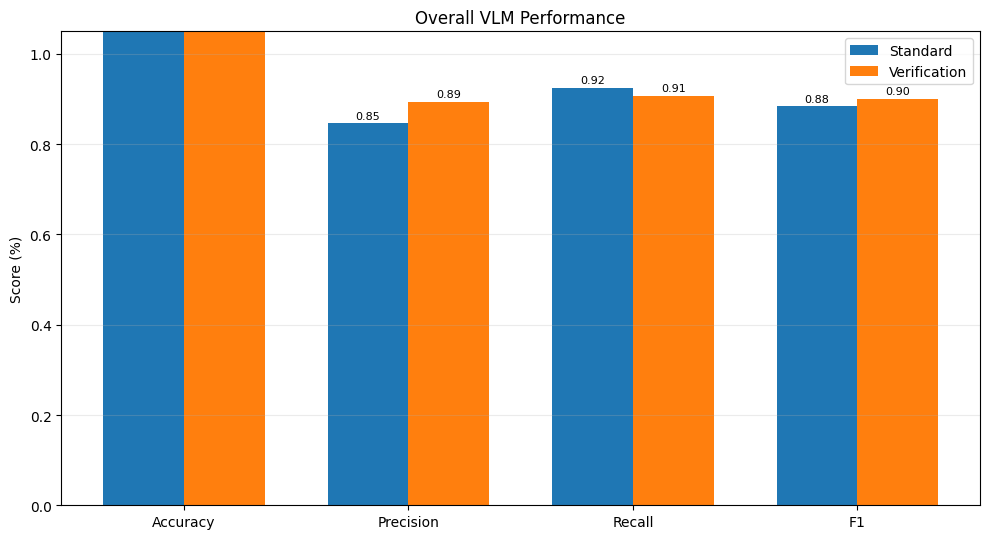

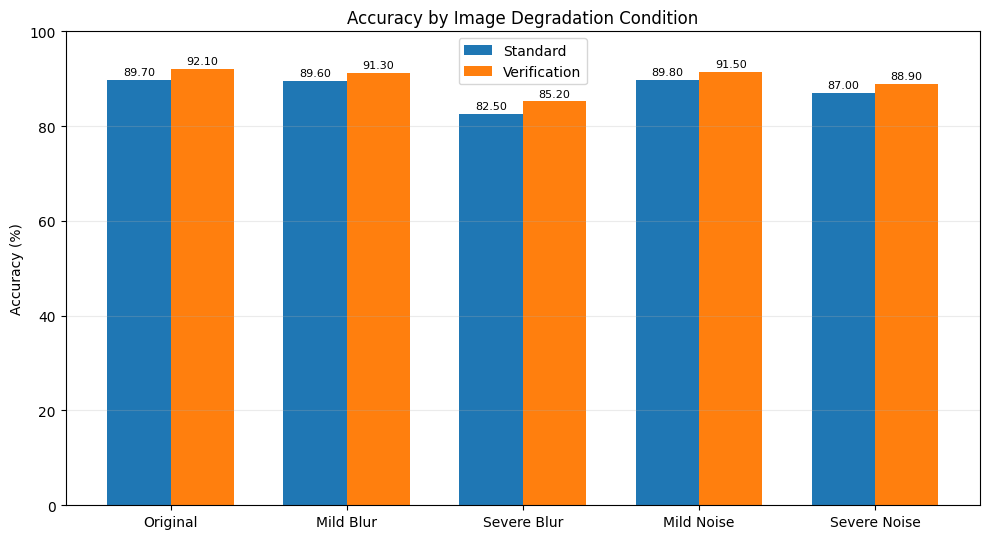

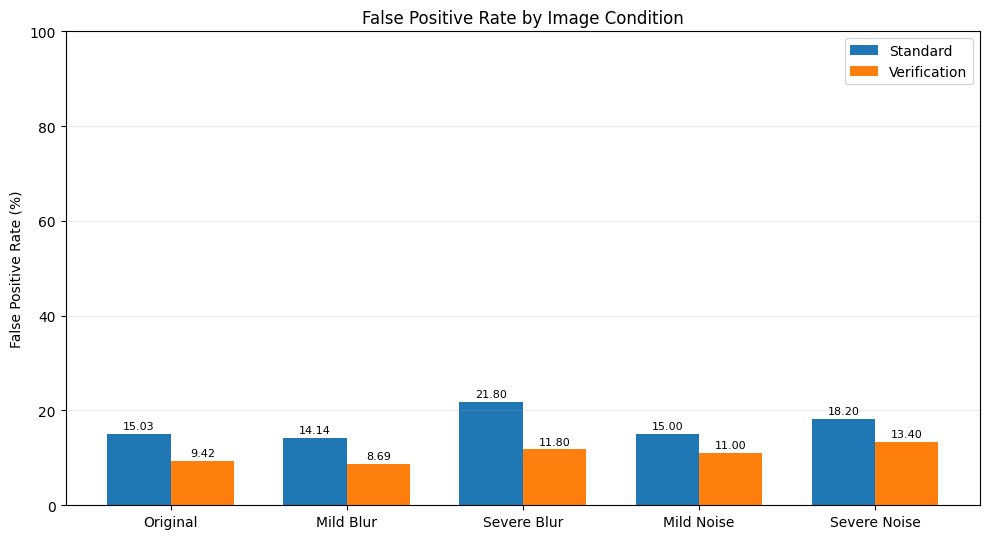

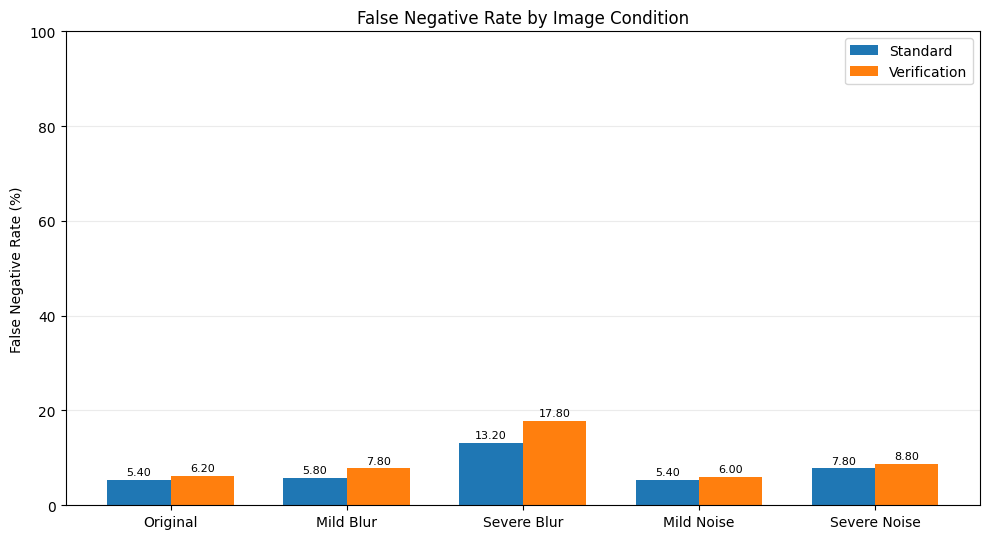

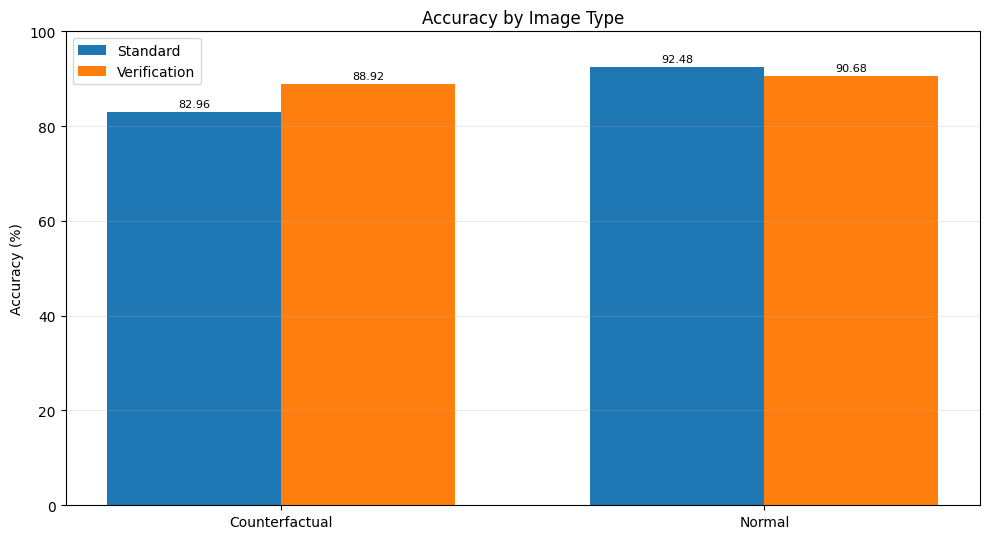


ALL GRAPHS AND METRIC TABLES GENERATED!
ZIP file: /content/VLM_Research_Analysis.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
from google.colab import files
from sklearn.metrics import precision_score, recall_score, f1_score

# Confirm dataset
assert len(df) == 10000
assert df["example_id"].nunique() == 500

# Output folder in Colab's temporary storage
OUTPUT_DIR = "/content/VLM_Research_Analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df["prediction"] = df["prediction"].astype(str).str.strip().str.capitalize()
df["ground_truth"] = df["ground_truth"].astype(str).str.strip().str.capitalize()

# =========================================
# 1. METRIC CALCULATION
# =========================================

def calculate_metrics(group):
    total = len(group)
    valid = group[group["prediction"].isin(["Yes", "No"])]

    y_true = valid["ground_truth"]
    y_pred = valid["prediction"]

    tp = ((y_true == "Yes") & (y_pred == "Yes")).sum()
    tn = ((y_true == "No") & (y_pred == "No")).sum()
    fp = ((y_true == "No") & (y_pred == "Yes")).sum()
    fn = ((y_true == "Yes") & (y_pred == "No")).sum()

    correct = (group["prediction"] == group["ground_truth"]).sum()

    return {
        "total": total,
        "valid_answers": len(valid),
        "unclear": total - len(valid),
        "coverage_percent": len(valid) / total * 100,
        "all_record_accuracy_percent": correct / total * 100,
        "valid_answer_accuracy_percent": (
            (y_true == y_pred).mean() * 100 if len(valid) else np.nan
        ),
        "precision": precision_score(
            y_true, y_pred, pos_label="Yes", zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, pos_label="Yes", zero_division=0
        ),
        "f1_score": f1_score(
            y_true, y_pred, pos_label="Yes", zero_division=0
        ),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "FPR_percent": fp / (fp + tn) * 100 if fp + tn else np.nan,
        "FNR_percent": fn / (fn + tp) * 100 if fn + tp else np.nan
    }

# Overall metrics
overall = pd.DataFrame([
    {"prompt_type": prompt, **calculate_metrics(group)}
    for prompt, group in df.groupby("prompt_type")
])

# Condition metrics
condition_metrics = pd.DataFrame([
    {
        "condition": condition,
        "prompt_type": prompt,
        **calculate_metrics(group)
    }
    for (condition, prompt), group in df.groupby(
        ["condition", "prompt_type"]
    )
])

# Image type metrics
image_metrics = pd.DataFrame([
    {
        "image_type": image_type,
        "prompt_type": prompt,
        **calculate_metrics(group)
    }
    for (image_type, prompt), group in df.groupby(
        ["image_type", "prompt_type"]
    )
])

# Save tables
overall.to_csv(f"{OUTPUT_DIR}/overall_metrics.csv", index=False)
condition_metrics.to_csv(
    f"{OUTPUT_DIR}/condition_metrics.csv", index=False
)
image_metrics.to_csv(
    f"{OUTPUT_DIR}/image_type_metrics.csv", index=False
)

print("OVERALL METRICS")
display(overall.round(4))

print("CONDITION METRICS")
display(condition_metrics.round(4))

print("IMAGE TYPE METRICS")
display(image_metrics.round(4))

# =========================================
# 2. GRAPH GENERATION
# =========================================

conditions = [
    "original", "mild_blur", "severe_blur",
    "mild_noise", "severe_noise"
]

condition_labels = [
    "Original", "Mild Blur", "Severe Blur",
    "Mild Noise", "Severe Noise"
]

width = 0.36

def save_grouped_graph(title, ylabel, metric, labels, values_std,
                       values_ver, filename, ylim=None):

    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10, 5.5))

    ax.bar(x - width/2, values_std, width, label="Standard")
    ax.bar(x + width/2, values_ver, width, label="Verification")

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x, labels)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    if ylim:
        ax.set_ylim(*ylim)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)

    fig.tight_layout()
    fig.savefig(
        f"{OUTPUT_DIR}/{filename}",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# Graph 1: Overall performance
metrics = ["accuracy", "precision", "recall", "f1_score"]

save_grouped_graph(
    "Overall VLM Performance",
    "Score (%)",
    "overall",
    ["Accuracy", "Precision", "Recall", "F1"],
    [overall.set_index("prompt_type").loc["standard", m] * (
        1 if m != "accuracy" else 1
    ) for m in [
        "all_record_accuracy_percent",
        "precision", "recall", "f1_score"
    ]],
    [overall.set_index("prompt_type").loc["verification", m] * (
        1 if m != "accuracy" else 1
    ) for m in [
        "all_record_accuracy_percent",
        "precision", "recall", "f1_score"
    ]],
    "01_overall_performance.png",
    (0, 1.05)
)

# Graph 2: Accuracy by degradation condition
condition_index = condition_metrics.set_index(
    ["condition", "prompt_type"]
)

std_accuracy = [
    condition_index.loc[(c, "standard"), "all_record_accuracy_percent"]
    for c in conditions
]
ver_accuracy = [
    condition_index.loc[(c, "verification"), "all_record_accuracy_percent"]
    for c in conditions
]

save_grouped_graph(
    "Accuracy by Image Degradation Condition",
    "Accuracy (%)",
    "accuracy",
    condition_labels,
    std_accuracy,
    ver_accuracy,
    "02_accuracy_by_condition.png",
    (0, 100)
)

# Graph 3: False positive rate
std_fpr = [
    condition_index.loc[(c, "standard"), "FPR_percent"]
    for c in conditions
]
ver_fpr = [
    condition_index.loc[(c, "verification"), "FPR_percent"]
    for c in conditions
]

save_grouped_graph(
    "False Positive Rate by Image Condition",
    "False Positive Rate (%)",
    "fpr",
    condition_labels,
    std_fpr,
    ver_fpr,
    "03_false_positive_rate.png",
    (0, 100)
)

# Graph 4: False negative rate
std_fnr = [
    condition_index.loc[(c, "standard"), "FNR_percent"]
    for c in conditions
]
ver_fnr = [
    condition_index.loc[(c, "verification"), "FNR_percent"]
    for c in conditions
]

save_grouped_graph(
    "False Negative Rate by Image Condition",
    "False Negative Rate (%)",
    "fnr",
    condition_labels,
    std_fnr,
    ver_fnr,
    "04_false_negative_rate.png",
    (0, 100)
)

# Graph 5: Accuracy by image type
image_index = image_metrics.set_index(
    ["image_type", "prompt_type"]
)

image_labels = ["Counterfactual", "Normal"]

std_image_acc = [
    image_index.loc[(t, "standard"), "all_record_accuracy_percent"]
    for t in ["counterfactual", "normal"]
]

ver_image_acc = [
    image_index.loc[(t, "verification"), "all_record_accuracy_percent"]
    for t in ["counterfactual", "normal"]
]

save_grouped_graph(
    "Accuracy by Image Type",
    "Accuracy (%)",
    "image_accuracy",
    image_labels,
    std_image_acc,
    ver_image_acc,
    "05_accuracy_by_image_type.png",
    (0, 100)
)

# =========================================
# 3. ZIP ALL OUTPUTS AND DOWNLOAD
# =========================================

ZIP_FILE = "/content/VLM_Research_Analysis.zip"

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(OUTPUT_DIR):
        z.write(
            os.path.join(OUTPUT_DIR, filename),
            arcname=filename
        )

print("\nALL GRAPHS AND METRIC TABLES GENERATED!")
print("ZIP file:", ZIP_FILE)

files.download(ZIP_FILE)

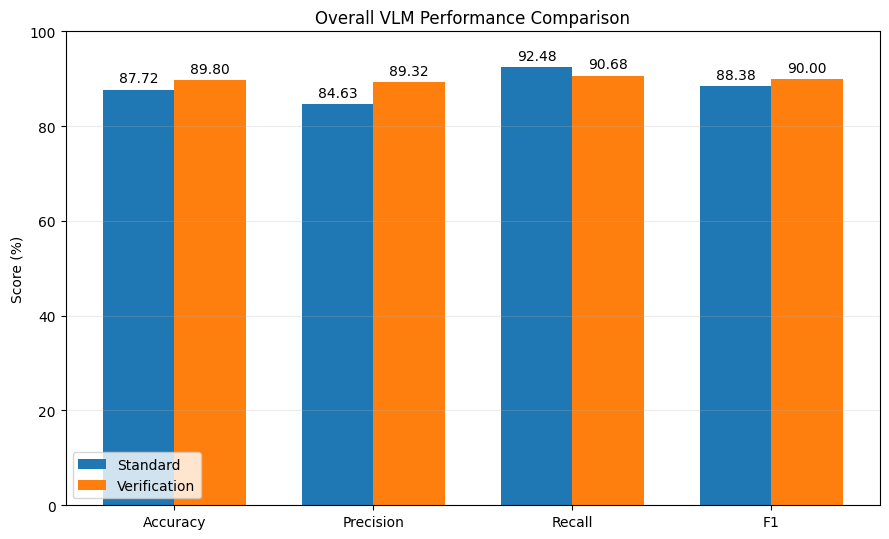

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

overall_index = overall.set_index("prompt_type")

metrics = ["Accuracy", "Precision", "Recall", "F1"]

standard_values = [
    overall_index.loc["standard", "all_record_accuracy_percent"],
    overall_index.loc["standard", "precision"] * 100,
    overall_index.loc["standard", "recall"] * 100,
    overall_index.loc["standard", "f1_score"] * 100
]

verification_values = [
    overall_index.loc["verification", "all_record_accuracy_percent"],
    overall_index.loc["verification", "precision"] * 100,
    overall_index.loc["verification", "recall"] * 100,
    overall_index.loc["verification", "f1_score"] * 100
]

x = np.arange(len(metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.bar(x - width/2, standard_values, width, label="Standard")
ax.bar(x + width/2, verification_values, width, label="Verification")

ax.set_title("Overall VLM Performance Comparison")
ax.set_ylabel("Score (%)")
ax.set_xticks(x, metrics)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig(
    "/content/VLM_Research_Analysis/01_overall_performance_corrected.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

from google.colab import files
files.download(
    "/content/VLM_Research_Analysis/01_overall_performance_corrected.png"
)

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import binomtest

# ==========================================
# 1. PREPARE PAIRED DATA
# ==========================================

data = df.copy()

data["correct"] = (
    data["prediction"] == data["ground_truth"]
).astype(int)

data["false_positive"] = (
    (data["image_type"] == "counterfactual") &
    (data["ground_truth"] == "No") &
    (data["prediction"] == "Yes")
).astype(int)

data["false_negative"] = (
    (data["image_type"] == "normal") &
    (data["ground_truth"] == "Yes") &
    (data["prediction"] == "No")
).astype(int)

PAIR_KEYS = ["example_id", "image_type", "condition"]

assert not data.duplicated(PAIR_KEYS + ["prompt_type"]).any()

wide = data.pivot(
    index=PAIR_KEYS,
    columns="prompt_type",
    values=["correct", "false_positive", "false_negative"]
)

assert wide.notna().all().all()
assert len(wide) == 5000

# Differences: positive means verification has a higher value.
wide["correct_diff"] = (
    wide[("correct", "verification")] -
    wide[("correct", "standard")]
)

wide["fp_diff"] = (
    wide[("false_positive", "verification")] -
    wide[("false_positive", "standard")]
)

wide["fn_diff"] = (
    wide[("false_negative", "verification")] -
    wide[("false_negative", "standard")]
)

# ==========================================
# 2. CLUSTER-LEVEL PERMUTATION TEST
# ==========================================

def cluster_permutation_test(differences, n_perm=100000, seed=42):
    """
    Sign-flip permutation test on independent example-level
    cluster means, preserving within-example dependencies.
    """

    differences = np.asarray(differences, dtype=float)
    differences = differences[~np.isnan(differences)]

    observed = differences.mean()
    rng = np.random.default_rng(seed)

    extreme = 0
    batch_size = 5000
    completed = 0

    while completed < n_perm:
        n = min(batch_size, n_perm - completed)

        signs = rng.choice(
            [-1, 1],
            size=(n, len(differences))
        )

        permuted = (signs * differences).mean(axis=1)

        extreme += np.sum(
            np.abs(permuted) >= abs(observed)
        )

        completed += n

    p_value = (extreme + 1) / (n_perm + 1)

    return observed, p_value, len(differences)

# ==========================================
# 3. CLUSTER BOOTSTRAP CONFIDENCE INTERVAL
# ==========================================

def cluster_bootstrap_ci(differences, n_boot=10000, seed=123):
    differences = np.asarray(differences, dtype=float)
    differences = differences[~np.isnan(differences)]

    rng = np.random.default_rng(seed)

    indices = rng.integers(
        0, len(differences),
        size=(n_boot, len(differences))
    )

    bootstrap_means = differences[indices].mean(axis=1)

    lower, upper = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    return lower, upper

# ==========================================
# 4. PREPARE EXAMPLE-LEVEL DIFFERENCES
# ==========================================

def example_level_difference(column, image_type=None, condition=None):
    subset = wide.reset_index()

    if image_type is not None:
        subset = subset[subset["image_type"] == image_type]

    if condition is not None:
        subset = subset[subset["condition"] == condition]

    return (
        subset.groupby("example_id")[column]
        .mean()
        .reindex(sorted(data["example_id"].unique()))
        .dropna()
        .values
    )

# Overall correctness
overall_diff = example_level_difference("correct_diff")

# Counterfactual false positives
fp_diff = example_level_difference(
    "fp_diff",
    image_type="counterfactual"
)

# Normal-image false negatives
fn_diff = example_level_difference(
    "fn_diff",
    image_type="normal"
)

# ==========================================
# 5. RUN PRIMARY TESTS
# ==========================================

test_definitions = [
    ("Overall correctness", overall_diff),
    ("Counterfactual false positives", fp_diff),
    ("Normal-image false negatives", fn_diff)
]

primary_results = []

for name, differences in test_definitions:
    estimate, p, n = cluster_permutation_test(differences)

    lower, upper = cluster_bootstrap_ci(differences)

    primary_results.append({
        "comparison": name,
        "examples": n,
        "verification_minus_standard_pp": estimate * 100,
        "95CI_lower_pp": lower * 100,
        "95CI_upper_pp": upper * 100,
        "p_value": p
    })

primary_results = pd.DataFrame(primary_results)

# ==========================================
# 6. CONDITION-SPECIFIC TESTS
# ==========================================

condition_results = []

for condition in [
    "original", "mild_blur", "severe_blur",
    "mild_noise", "severe_noise"
]:

    # Counterfactual false-positive differences
    differences = example_level_difference(
        "fp_diff",
        image_type="counterfactual",
        condition=condition
    )

    estimate, p, n = cluster_permutation_test(differences)

    lower, upper = cluster_bootstrap_ci(differences)

    condition_results.append({
        "condition": condition,
        "examples": n,
        "verification_minus_standard_fp_pp": estimate * 100,
        "95CI_lower_pp": lower * 100,
        "95CI_upper_pp": upper * 100,
        "p_value": p
    })

condition_results = pd.DataFrame(condition_results)

# ==========================================
# 7. HOLM MULTIPLE-TEST CORRECTION
# ==========================================

def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)

    order = np.argsort(p_values)
    adjusted = np.empty(n)

    running_max = 0

    for rank, index in enumerate(order):
        value = (n - rank) * p_values[index]
        running_max = max(running_max, value)
        adjusted[index] = min(running_max, 1.0)

    return adjusted

condition_results["holm_adjusted_p"] = holm_adjust(
    condition_results["p_value"].values
)

condition_results["significant_after_holm"] = (
    condition_results["holm_adjusted_p"] < 0.05
)

# ==========================================
# 8. DISPLAY AND SAVE RESULTS
# ==========================================

print("========== PRIMARY STATISTICAL TESTS ==========")
display(primary_results.round(5))

print("\n========== CONDITION-SPECIFIC TESTS ==========")
display(condition_results.round(5))

primary_results.to_csv(
    "/content/primary_statistical_results.csv",
    index=False
)

condition_results.to_csv(
    "/content/condition_statistical_results.csv",
    index=False
)

print("\nStatistical results saved successfully.")

from google.colab import files

files.download("/content/primary_statistical_results.csv")
files.download("/content/condition_statistical_results.csv")

========== PRIMARY STATISTICAL TESTS ==========


,comparison,examples,verification_minus_standard_pp,95CI_lower_pp,95CI_upper_pp,p_value
0,Overall correctness,500,2.08,1.44,2.76,0.00001
1,Counterfactual false positives,500,-5.96,-7.16,-4.84,0.00001
2,Normal-image false negatives,500,1.80,1.20,2.44,0.00001



========== CONDITION-SPECIFIC TESTS ==========


,condition,examples,verification_minus_standard_fp_pp,95CI_lower_pp,95CI_upper_pp,p_value,holm_adjusted_p,significant_after_holm
0,original,500,-5.6,-7.8,-3.6,0.00001,0.00005,True
1,mild_blur,500,-5.4,-7.4,-3.6,0.00001,0.00005,True
2,severe_blur,500,-10.0,-12.8,-7.4,0.00001,0.00005,True
3,mild_noise,500,-4.0,-6.0,-2.2,0.00002,0.00005,True
4,severe_noise,500,-4.8,-7.0,-2.8,0.00001,0.00005,True



Statistical results saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files

# =====================================
# 1. VERIFY MASTER DATASET
# =====================================

assert len(df) == 10000
assert df["example_id"].nunique() == 500

ml_df = df.copy()

# Normalize labels
ml_df["prediction"] = (
    ml_df["prediction"].astype(str).str.strip().str.capitalize()
)

ml_df["ground_truth"] = (
    ml_df["ground_truth"].astype(str).str.strip().str.capitalize()
)

# =====================================
# 2. CREATE TARGET VARIABLE
# =====================================

ml_df["is_error"] = (
    ml_df["prediction"] != ml_df["ground_truth"]
).astype(int)

# =====================================
# 3. SELECT INPUT FEATURES
# =====================================

FEATURES = [
    "condition",
    "prompt_type",
    "target_object",
    "question"
]

TARGET = "is_error"
GROUP = "example_id"

# Keep only necessary columns
ml_dataset = ml_df[
    FEATURES + [TARGET, GROUP]
].copy()

# Remove missing feature rows, if any
ml_dataset = ml_dataset.dropna(
    subset=FEATURES + [TARGET, GROUP]
)

# =====================================
# 4. DISPLAY DATASET SUMMARY
# =====================================

print("========== ML DATASET SUMMARY ==========")

print("Total records:", len(ml_dataset))
print("Unique examples:", ml_dataset[GROUP].nunique())

print("\nTarget distribution:")
print(
    ml_dataset[TARGET]
    .value_counts()
    .rename(index={0: "Correct", 1: "Incorrect"})
)

print("\nTarget percentage:")
print(
    ml_dataset[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .rename(index={0: "Correct", 1: "Incorrect"})
    .round(2)
)

print("\nFeature columns:")
print(FEATURES)

print("\nMissing values:")
print(ml_dataset.isnull().sum())

print("\nSample records:")
display(ml_dataset.head())

# =====================================
# 5. VALIDATE AND EXPORT
# =====================================

assert len(ml_dataset) == 10000
assert ml_dataset[GROUP].nunique() == 500
assert set(ml_dataset[TARGET].unique()) == {0, 1}

ml_dataset.to_csv(
    "vlm_ml_classification_dataset.csv",
    index=False
)

print("\nML DATASET CREATED SUCCESSFULLY!")

files.download("vlm_ml_classification_dataset.csv")

========== ML DATASET SUMMARY ==========
Total records: 10000
Unique examples: 500

Target distribution:
is_error
Correct      8876
Incorrect    1124
Name: count, dtype: int64

Target percentage:
is_error
Correct      88.76
Incorrect    11.24
Name: proportion, dtype: float64

Feature columns:
['condition', 'prompt_type', 'target_object', 'question']

Missing values:
condition        0
prompt_type      0
target_object    0
question         0
is_error         0
example_id       0
dtype: int64

Sample records:


,condition,prompt_type,target_object,question,is_error,example_id
0,original,standard,hair drier,Is there a hair drier in the image?,0,popev2-000000006578
1,original,verification,hair drier,Is there a hair drier in the image?,0,popev2-000000006578
2,mild_blur,standard,hair drier,Is there a hair drier in the image?,0,popev2-000000006578
3,mild_blur,verification,hair drier,Is there a hair drier in the image?,0,popev2-000000006578
4,severe_blur,standard,hair drier,Is there a hair drier in the image?,0,popev2-000000006578



ML DATASET CREATED SUCCESSFULLY!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Load uploaded ML dataset
ml_dataset = pd.read_csv("vlm_ml_classification_dataset.csv")

# Combine text features
ml_dataset["combined_text"] = (
    ml_dataset["target_object"].astype(str)
    + " "
    + ml_dataset["question"].astype(str)
)

# Define inputs and target
X = ml_dataset[
    ["condition", "prompt_type", "combined_text"]
]

y = ml_dataset["is_error"]
groups = ml_dataset["example_id"]

# Group-based 80:20 split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

# Confirm no example leakage
assert set(train_groups).isdisjoint(set(test_groups))

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["condition", "prompt_type"]
        ),
        (
            "text",
            TfidfVectorizer(
                max_features=3000,
                ngram_range=(1, 2),
                stop_words="english"
            ),
            "combined_text"
        )
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("========== FEATURE ENGINEERING SUMMARY ==========")

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training examples:", train_groups.nunique())
print("Testing examples:", test_groups.nunique())

print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTraining feature matrix:", X_train_processed.shape)
print("Testing feature matrix:", X_test_processed.shape)

print("\nOverlapping example IDs:",
      len(set(train_groups) & set(test_groups)))

print("\nFEATURE ENGINEERING COMPLETED!")

========== FEATURE ENGINEERING SUMMARY ==========
Training records: 8000
Testing records: 2000
Training examples: 400
Testing examples: 100
Training target distribution:
is_error
0    7123
1     877
Name: count, dtype: int64

Testing target distribution:
is_error
0    1753
1     247
Name: count, dtype: int64

Training feature matrix: (8000, 271)
Testing feature matrix: (2000, 271)

Overlapping example IDs: 0

FEATURE ENGINEERING COMPLETED!


In [ ]:
import pandas as pd
import numpy as np
import time

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ==========================================
# 1. INITIALIZE MODELS
# ==========================================

logistic = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

random_forest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

svm = SVC(
    kernel="linear",
    C=1.0,
    class_weight="balanced",
    probability=True,
    random_state=42
)

voting = VotingClassifier(
    estimators=[
        ("lr", logistic),
        ("rf", random_forest),
        ("svm", svm)
    ],
    voting="soft",
    weights=[1, 1, 1],
    n_jobs=-1
)

models = {
    "Logistic Regression": logistic,
    "Random Forest": random_forest,
    "SVM": svm,
    "Voting Classifier": voting
}

# ==========================================
# 2. TRAIN AND EVALUATE
# ==========================================

results = []
confusion_matrices = {}

for name, model in models.items():

    print("\nTraining:", name)

    start_time = time.time()

    model.fit(X_train_processed, y_train)

    training_time = time.time() - start_time

    # Predictions
    y_pred = model.predict(X_test_processed)

    # Probability of the error class
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    balanced_acc = balanced_accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    cm = confusion_matrix(y_test, y_pred)
    confusion_matrices[name] = cm

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_acc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc,
        "Training Time (seconds)": training_time,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })

    print("Training time:", round(training_time, 2), "seconds")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1:", round(f1, 4))
    print("ROC AUC:", round(roc_auc, 4))

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Correct", "Incorrect"],
            zero_division=0
        )
    )

# ==========================================
# 3. COMPARISON TABLE
# ==========================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n========== FINAL MODEL COMPARISON ==========")
display(results_df.round(4))

# ==========================================
# 4. SAVE RESULTS TO PC
# ==========================================

results_df.to_csv(
    "vlm_ml_model_comparison.csv",
    index=False
)

from google.colab import files
files.download("vlm_ml_model_comparison.csv")

print("\nALL FOUR MODELS TRAINED AND EVALUATED!")


Training: Logistic Regression
Training time: 0.29 seconds
Accuracy: 0.6245
Precision: 0.1769
Recall: 0.5587
F1: 0.2687
ROC AUC: 0.6366

Classification report:
              precision    recall  f1-score   support

     Correct       0.91      0.63      0.75      1753
   Incorrect       0.18      0.56      0.27       247

    accuracy                           0.62      2000
   macro avg       0.54      0.60      0.51      2000
weighted avg       0.82      0.62      0.69      2000


Training: Random Forest
Training time: 16.15 seconds
Accuracy: 0.6855
Precision: 0.1817
Recall: 0.4413
F1: 0.2574
ROC AUC: 0.6116

Classification report:
              precision    recall  f1-score   support

     Correct       0.90      0.72      0.80      1753
   Incorrect       0.18      0.44      0.26       247

    accuracy                           0.69      2000
   macro avg       0.54      0.58      0.53      2000
weighted avg       0.81      0.69      0.73      2000


Training: SVM
Training time: 1

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time (seconds),TN,FP,FN,TP
0,Logistic Regression,0.6245,0.5962,0.1769,0.5587,0.2687,0.6366,0.2927,1111,642,109,138
1,Random Forest,0.6855,0.5806,0.1817,0.4413,0.2574,0.6116,16.1493,1262,491,138,109
2,SVM,0.6235,0.5765,0.1671,0.5142,0.2522,0.5873,14.6494,1120,633,120,127
3,Voting Classifier,0.8005,0.5401,0.1935,0.1943,0.1939,0.6297,22.7326,1553,200,199,48


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL FOUR MODELS TRAINED AND EVALUATED!


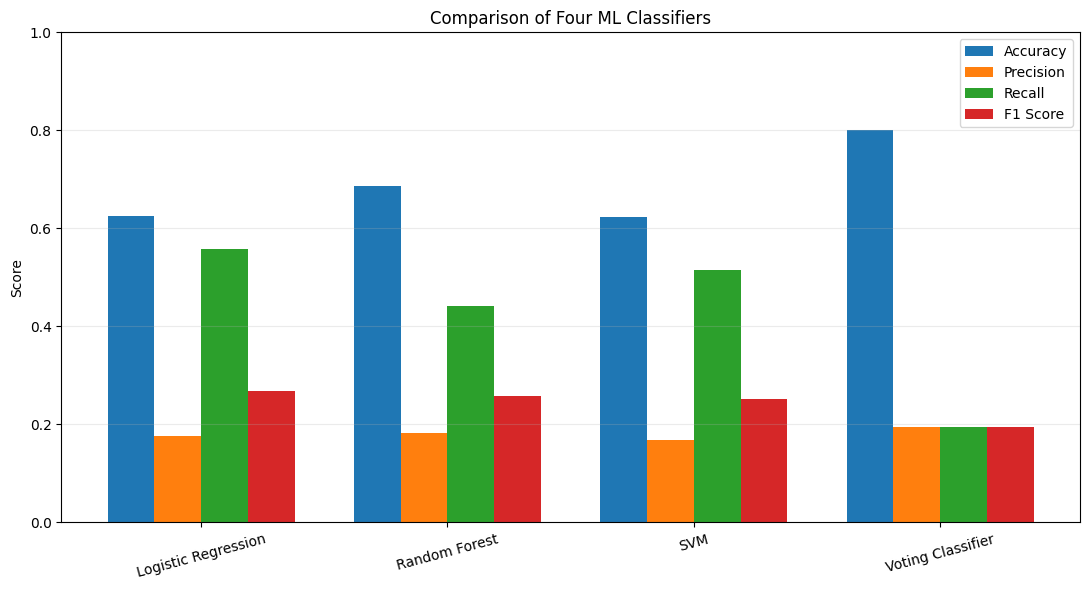

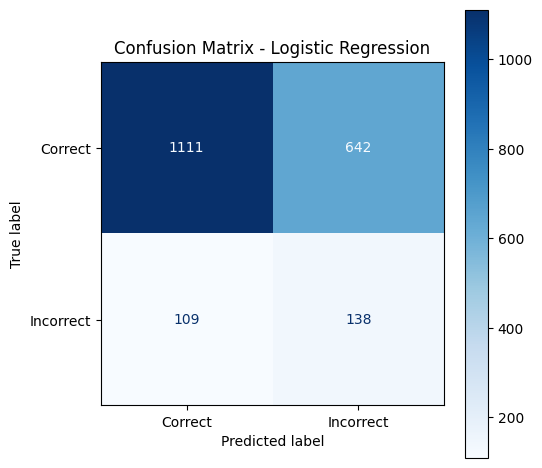

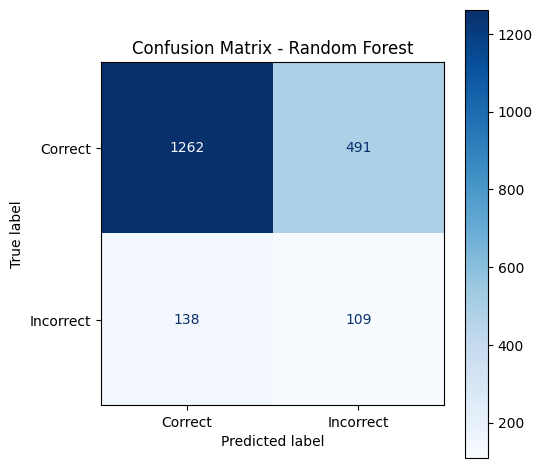

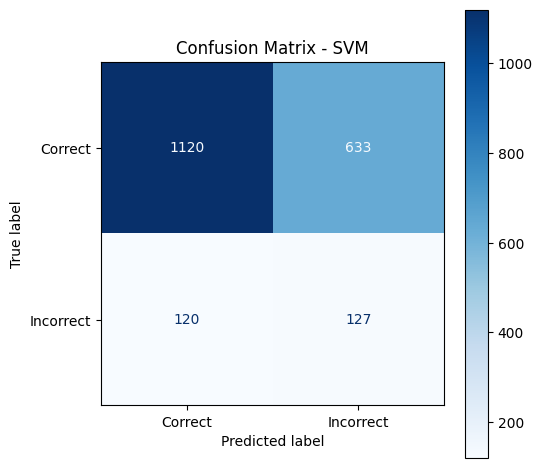

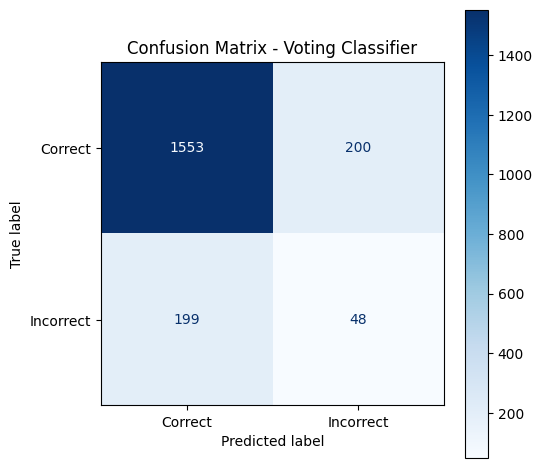

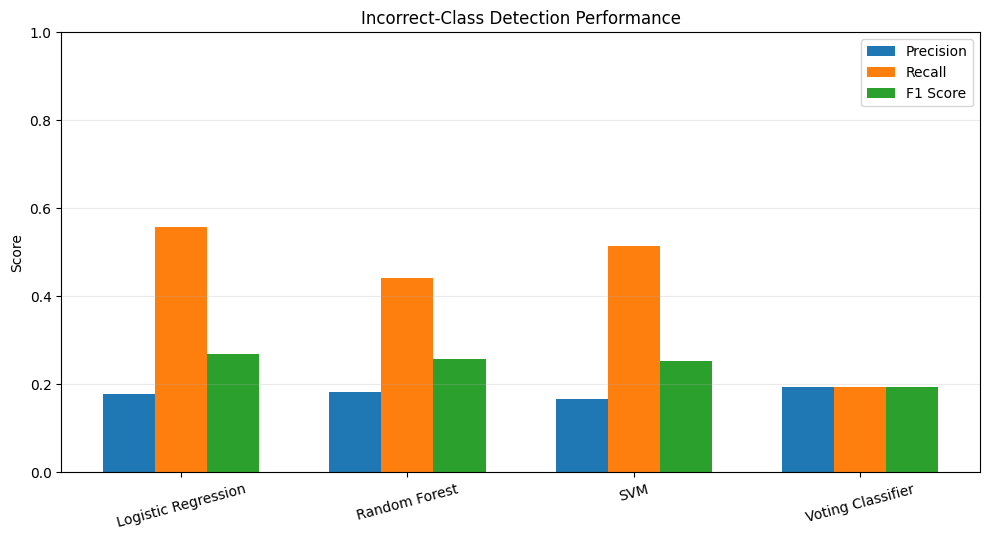

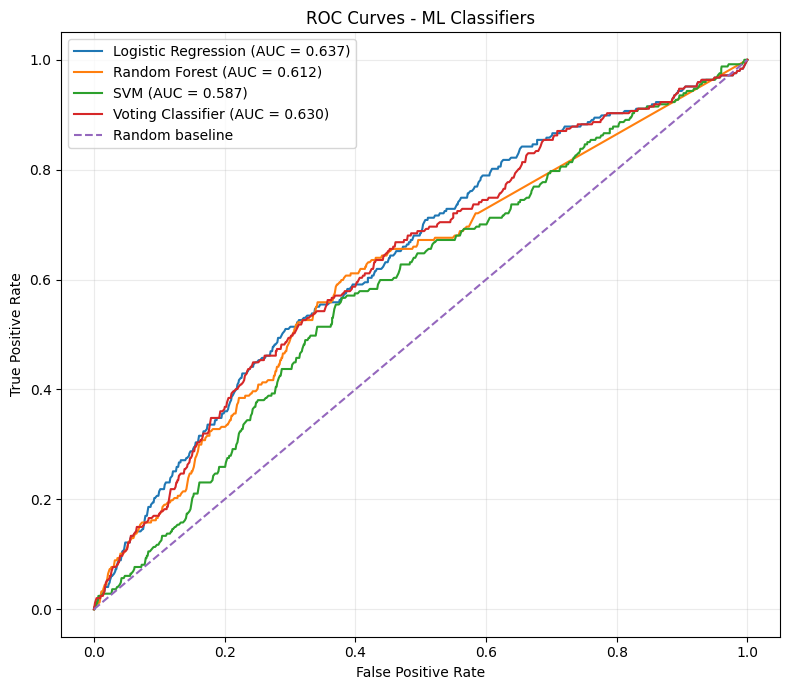

All ML graphs generated!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import zipfile
import os

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)
from google.colab import files

ML_GRAPH_DIR = "/content/ML_Model_Graphs"
os.makedirs(ML_GRAPH_DIR, exist_ok=True)

# 1. Performance comparison
plot_metrics = [
    ("Accuracy", "Accuracy"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("F1 Score", "F1 Score")
]

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(results_df))
width = 0.19

for i, (column, label) in enumerate(plot_metrics):
    ax.bar(
        x + (i - 1.5) * width,
        results_df[column],
        width,
        label=label
    )

ax.set_xticks(x, results_df["Model"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("Comparison of Four ML Classifiers")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(f"{ML_GRAPH_DIR}/01_model_comparison.png", dpi=250)
plt.show()
plt.close()

# 2. Confusion matrices
for name, model in models.items():
    predictions = model.predict(X_test_processed)

    fig, ax = plt.subplots(figsize=(5.5, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Correct", "Incorrect"],
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"Confusion Matrix - {name}")
    plt.tight_layout()

    safe_name = name.lower().replace(" ", "_")
    plt.savefig(
        f"{ML_GRAPH_DIR}/02_confusion_{safe_name}.png",
        dpi=250
    )
    plt.show()
    plt.close()

# 3. Error-class metric comparison
fig, ax = plt.subplots(figsize=(10, 5.5))

metric_names = ["Precision", "Recall", "F1 Score"]
x = np.arange(len(results_df))
width = 0.23

for i, metric in enumerate(metric_names):
    ax.bar(
        x + (i - 1) * width,
        results_df[metric],
        width,
        label=metric
    )

ax.set_xticks(x, results_df["Model"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("Incorrect-Class Detection Performance")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(f"{ML_GRAPH_DIR}/07_error_class_metrics.png", dpi=250)
plt.show()
plt.close()

# 4. ROC curves
fig, ax = plt.subplots(figsize=(8, 7))

for name, model in models.items():
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    roc_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves - ML Classifiers")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(f"{ML_GRAPH_DIR}/08_roc_curves.png", dpi=250)
plt.show()
plt.close()

# 5. Package graphs
zip_path = "/content/ML_Model_Graphs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(ML_GRAPH_DIR):
        z.write(
            os.path.join(ML_GRAPH_DIR, filename),
            arcname=filename
        )

print("All ML graphs generated!")
files.download(zip_path)

In [ ]:
# Check whether our existing ML dataset and split are available

required_variables = [
    "df", "ml_dataset",
    "X_train", "X_test",
    "y_train", "y_test",
    "models"
]

for var in required_variables:
    print(f"{var}: {'Available' if var in globals() else 'Missing'}")

print("\nDataset shape:", ml_dataset.shape)
print("Dataset columns:", ml_dataset.columns.tolist())

print("\nTraining examples:", len(X_train))
print("Testing examples:", len(X_test))

print("\nTraining error distribution:")
print(y_train.value_counts())

print("\nTesting error distribution:")
print(y_test.value_counts())

df: Available
ml_dataset: Available
X_train: Available
X_test: Available
y_train: Available
y_test: Available
models: Available

Dataset shape: (10000, 7)
Dataset columns: ['condition', 'prompt_type', 'target_object', 'question', 'is_error', 'example_id', 'combined_text']

Training examples: 8000
Testing examples: 2000

Training error distribution:
is_error
0    7123
1     877
Name: count, dtype: int64

Testing error distribution:
is_error
0    1753
1     247
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

# Recreate the original group-based 80/20 split
data = ml_dataset.reset_index(drop=True).copy()

X = data[["condition", "prompt_type", "combined_text"]]
y = data["is_error"].astype(int)
groups = data["example_id"]

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train_raw = X.iloc[train_idx].copy()
y_train_cv = y.iloc[train_idx].copy()
groups_train = groups.iloc[train_idx].copy()

X_test_check = X.iloc[test_idx].copy()
y_test_check = y.iloc[test_idx].copy()

# Confirm this reproduces the original split
assert len(train_idx) == 8000
assert len(test_idx) == 2000
assert y_train_cv.value_counts().sort_index().equals(
    y_train.reset_index(drop=True).value_counts().sort_index()
), "Training split does not match the original split!"

print("Original split reproduced successfully.")
print("Training rows:", len(X_train_raw))
print("Testing rows:", len(X_test_check))
print("Training groups:", groups_train.nunique())
print("Test groups:", groups.iloc[test_idx].nunique())

# Preprocessing is fitted independently inside every CV fold
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "text",
                TfidfVectorizer(
                    max_features=3000,
                    ngram_range=(1, 2),
                    stop_words="english"
                ),
                "combined_text"
            ),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                ["condition", "prompt_type"]
            )
        ]
    )

models_cv = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []
oof_predictions = {}

for model_name, classifier in models_cv.items():

    print(f"\nRunning: {model_name}")

    oof_probabilities = np.full(len(X_train_raw), np.nan)

    for fold, (tr_idx, val_idx) in enumerate(
        cv.split(X_train_raw, y_train_cv, groups_train), start=1
    ):
        pipeline = Pipeline([
            ("preprocessor", make_preprocessor()),
            ("classifier", classifier)
        ])

        pipeline.fit(
            X_train_raw.iloc[tr_idx],
            y_train_cv.iloc[tr_idx]
        )

        probabilities = pipeline.predict_proba(
            X_train_raw.iloc[val_idx]
        )[:, 1]

        oof_probabilities[val_idx] = probabilities

        fold_predictions = (probabilities >= 0.5).astype(int)

        print(
            f"Fold {fold}: "
            f"F1={f1_score(y_train_cv.iloc[val_idx], fold_predictions):.4f}, "
            f"Recall={recall_score(y_train_cv.iloc[val_idx], fold_predictions):.4f}"
        )

    assert not np.isnan(oof_probabilities).any()

    oof_predictions[model_name] = oof_probabilities
    predictions = (oof_probabilities >= 0.5).astype(int)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_train_cv, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_train_cv, predictions),
        "Precision": precision_score(y_train_cv, predictions, zero_division=0),
        "Recall": recall_score(y_train_cv, predictions, zero_division=0),
        "F1": f1_score(y_train_cv, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_train_cv, oof_probabilities),
        "PR-AUC": average_precision_score(y_train_cv, oof_probabilities)
    }

    cv_results.append(metrics)

cv_results_df = pd.DataFrame(cv_results)

print("\n========== 5-FOLD GROUP CV RESULTS ==========")
display(cv_results_df.round(4))

# Save results
cv_results_df.to_csv("group_cv_results.csv", index=False)

print("\nSaved: group_cv_results.csv")

Original split reproduced successfully.
Training rows: 8000
Testing rows: 2000
Training groups: 400
Test groups: 100

Running: Logistic Regression
Fold 1: F1=0.2222, Recall=0.5060
Fold 2: F1=0.2354, Recall=0.5549
Fold 3: F1=0.2394, Recall=0.5197
Fold 4: F1=0.2771, Recall=0.6250
Fold 5: F1=0.2708, Recall=0.4776

Running: Random Forest
Fold 1: F1=0.2050, Recall=0.3434
Fold 2: F1=0.2572, Recall=0.4396
Fold 3: F1=0.2218, Recall=0.3487
Fold 4: F1=0.2778, Recall=0.4545
Fold 5: F1=0.2400, Recall=0.3134

========== 5-FOLD GROUP CV RESULTS ==========


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.6454,0.5974,0.1621,0.5359,0.2489,0.6312,0.1719
1,Random Forest,0.7386,0.5813,0.1771,0.3797,0.2416,0.6224,0.1678



Saved: group_cv_results.csv


In [ ]:
from sklearn.metrics import precision_recall_curve
import pandas as pd
import numpy as np

threshold_results = []
best_thresholds = {}

for model_name, probabilities in oof_predictions.items():

    precision, recall, thresholds = precision_recall_curve(
        y_train_cv, probabilities
    )

    # Calculate F1 for each available threshold
    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-12)
    )

    # Select threshold giving maximum training OOF F1
    best_idx = np.argmax(f1_values)
    best_threshold = thresholds[best_idx]

    best_thresholds[model_name] = best_threshold

    # Baseline threshold = 0.50
    baseline_predictions = (probabilities >= 0.50).astype(int)
    optimized_predictions = (
        probabilities >= best_threshold
    ).astype(int)

    threshold_results.append({
        "Model": model_name,
        "Threshold": best_threshold,
        "Baseline F1": f1_score(
            y_train_cv, baseline_predictions
        ),
        "Optimized F1": f1_score(
            y_train_cv, optimized_predictions
        ),
        "Baseline Recall": recall_score(
            y_train_cv, baseline_predictions
        ),
        "Optimized Recall": recall_score(
            y_train_cv, optimized_predictions
        ),
        "Optimized Precision": precision_score(
            y_train_cv, optimized_predictions,
            zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

print("========== THRESHOLD OPTIMIZATION ==========")
display(threshold_results_df.round(4))

print("\nSelected thresholds:")
for name, threshold in best_thresholds.items():
    print(f"{name}: {threshold:.4f}")

threshold_results_df.to_csv(
    "threshold_optimization_results.csv",
    index=False
)

print("\nSaved: threshold_optimization_results.csv")

========== THRESHOLD OPTIMIZATION ==========


,Model,Threshold,Baseline F1,Optimized F1,Baseline Recall,Optimized Recall,Optimized Precision
0,Logistic Regression,0.4620,0.2489,0.2508,0.5359,0.5952,0.1589
1,Random Forest,0.4871,0.2416,0.2432,0.3797,0.3900,0.1767



Selected thresholds:
Logistic Regression: 0.4620
Random Forest: 0.4871

Saved: threshold_optimization_results.csv


In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

final_models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

final_results = []
final_confusion_matrices = {}

for name, classifier in final_models.items():

    print(f"\nTraining final {name}...")

    final_pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", classifier)
    ])

    # Train using only the 8,000 training records
    final_pipeline.fit(X_train_raw, y_train_cv)

    # Predict probabilities on the untouched test set
    test_probabilities = final_pipeline.predict_proba(
        X_test_check
    )[:, 1]

    selected_threshold = best_thresholds[name]

    for threshold_label, threshold in [
        ("Default 0.50", 0.50),
        ("Optimized", selected_threshold)
    ]:

        predictions = (test_probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test_check, predictions, labels=[0, 1]
        ).ravel()

        metrics = {
            "Model": name,
            "Threshold Type": threshold_label,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test_check, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                y_test_check, predictions
            ),
            "Precision": precision_score(
                y_test_check, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test_check, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test_check, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_test_check, test_probabilities
            ),
            "PR-AUC": average_precision_score(
                y_test_check, test_probabilities
            ),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        }

        final_results.append(metrics)

        final_confusion_matrices[
            f"{name} - {threshold_label}"
        ] = confusion_matrix(
            y_test_check, predictions, labels=[0, 1]
        )

        print(f"\n{name} | {threshold_label}")
        print("Threshold:", round(threshold, 4))
        print(classification_report(
            y_test_check,
            predictions,
            target_names=["Correct", "Incorrect"],
            zero_division=0
        ))

final_results_df = pd.DataFrame(final_results)

print("\n========== FINAL HELD-OUT TEST RESULTS ==========")
display(final_results_df.round(4))

final_results_df.to_csv(
    "final_ml_test_results.csv", index=False
)

print("\nSaved: final_ml_test_results.csv")


Training final Logistic Regression...

Logistic Regression | Default 0.50
Threshold: 0.5
              precision    recall  f1-score   support

     Correct       0.91      0.63      0.75      1753
   Incorrect       0.18      0.56      0.27       247

    accuracy                           0.62      2000
   macro avg       0.54      0.60      0.51      2000
weighted avg       0.82      0.62      0.69      2000


Logistic Regression | Optimized
Threshold: 0.462
              precision    recall  f1-score   support

     Correct       0.91      0.61      0.73      1753
   Incorrect       0.17      0.58      0.27       247

    accuracy                           0.61      2000
   macro avg       0.54      0.60      0.50      2000
weighted avg       0.82      0.61      0.67      2000


Training final Random Forest...

Random Forest | Default 0.50
Threshold: 0.5
              precision    recall  f1-score   support

     Correct       0.90      0.72      0.80      1753
   Incorrect       

,Model,Threshold Type,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Logistic Regression,Default 0.50,0.5000,0.6245,0.5962,0.1769,0.5587,0.2687,0.6366,0.1919,1111,642,109,138
1,Logistic Regression,Optimized,0.4620,0.6055,0.5958,0.1735,0.5830,0.2674,0.6366,0.1919,1067,686,103,144
2,Random Forest,Default 0.50,0.5000,0.6855,0.5806,0.1817,0.4413,0.2574,0.6068,0.1788,1262,491,138,109
3,Random Forest,Optimized,0.4871,0.6795,0.5841,0.1823,0.4575,0.2607,0.6068,0.1788,1246,507,134,113



Saved: final_ml_test_results.csv
